# Severe-wasting prediction: reproducible nested-CV pipeline

**Goal.** Improve out-of-sample *ranking* of children at risk of severe wasting (`severe_wasting`, WHZ < -3, prevalence about 2.5%) without leakage or overfitting, and measure honestly whether anything beat the simple baselines.

**Accuracy is not the objective.** Predicting "no child is wasted" is about 97.5% accurate and finds nobody. Every comparison therefore uses weighted and unweighted **ROC-AUC, PR-AUC, Brier score, calibration slope/intercept and top-decile case capture**, judged against an age + sex logistic regression and a full survey-weighted logistic regression.

## How to run
1. Put `MICS-child-ISRC.dta` next to this notebook (optionally also `MICS-child-ISRC-revised.dta`, which enables the clearly labelled post-hoc feature set FS2).
2. `pip install pandas numpy scipy scikit-learn>=1.2 matplotlib xgboost lightgbm catboost shap` (xgboost, lightgbm, catboost and shap are optional; missing ones are skipped).
3. Choose a compute profile with the environment variable `WASTING_PROFILE` (`smoke` = code test on a data subsample, `standard` = default, `extended` = bigger tuning budget and more seeds), then *Restart & Run All*. Finished experiment blocks are cached in `outputs/cache/`, so an interrupted run resumes.

## Sections
| # | Section | What it does |
|---|---|---|
| 1 | Setup and configuration | Imports, optional dependencies, compute profile, seeds |
| 2 | Data loading and leakage guard | Loads data, validates columns, separates outcome-derived columns |
| 3 | Variable and coding audit | Labels, value coding, missingness, sparse categories |
| 4 | Cohorts | All children, ages 0-1, ages 2-4 |
| 5 | Feature sets | FS0 original, FS1 engineered, FS2 extended (post hoc) |
| 6 | CV machinery | Nested grouped splits, weighted metrics, models, custom weighted inner search |
| 7 | Reference: default trees | Preserved diagnostic showing overfitting of untuned trees |
| 8 | Nested-CV experiments | The main run (3 seeds x 5 outer x 3 inner folds) |
| 9-13 | Results | Comparison table, overfitting gaps, seed stability, cluster-bootstrap CIs, calibration |
| 14 | Model selection | Pre-declared rule that prefers the simplest stable model |
| 15 | Permutation check and SHAP | Finalist only |
| 16 | Findings and limitations | Auto-generated from the saved results |

In [1]:
# ===== 1. Imports, optional dependencies and compute profile =====
import warnings, os, sys, time, json, hashlib, pickle, platform, itertools
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, norm
from pandas.io.stata import StataReader
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

_skv = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
if _skv < (1, 2):
    raise RuntimeError(f'scikit-learn >= 1.2 is required (found {sklearn.__version__}). Run: pip install -U scikit-learn')

# Optional model families / SHAP: skipped gracefully when not installed.
OPTIONAL = {}
for _name, _imp in [('xgboost', 'from xgboost import XGBClassifier'), ('lightgbm', 'from lightgbm import LGBMClassifier'),
                    ('catboost', 'from catboost import CatBoostClassifier'), ('shap', 'import shap')]:
    try:
        exec(_imp); OPTIONAL[_name] = True
    except Exception as _e:
        OPTIONAL[_name] = False
print('Optional packages available:', OPTIONAL)

# ---- Compute profiles (only the budget differs; the validation design is identical) ----
PROFILES = {
    # 'smoke' is ONLY a code test: it subsamples PSUs and must never be used for reported results.
    'smoke':    dict(seeds=(42,),            n_tune_iter=1,  n_boot=30,   n_perm=2,   shap_n=100,  psu_frac=0.25),
    'standard': dict(seeds=(42, 43, 44),     n_tune_iter=4,  n_boot=300,  n_perm=30,  shap_n=500,  psu_frac=1.0),
    'extended': dict(seeds=(42, 43, 44, 45, 46), n_tune_iter=12, n_boot=1000, n_perm=100, shap_n=1000, psu_frac=1.0),
}
PROFILE = os.environ.get('WASTING_PROFILE', 'standard')
if PROFILE not in PROFILES:
    raise ValueError(f'Unknown WASTING_PROFILE={PROFILE!r}; choose one of {list(PROFILES)}')
P = PROFILES[PROFILE]
SEEDS, N_TUNE_ITER, N_BOOT, N_PERM, SHAP_N, PSU_FRAC = P['seeds'], P['n_tune_iter'], P['n_boot'], P['n_perm'], P['shap_n'], P['psu_frac']
N_OUTER, N_INNER = 5, 3                      # fixed by the study design
N_JOBS = int(os.environ.get('WASTING_N_JOBS', max(1, min(4, os.cpu_count() or 1))))
RUN_SHAP = OPTIONAL['shap'] and os.environ.get('WASTING_SHAP', '1') == '1'
RESUME = os.environ.get('WASTING_RESUME', '1') == '1'
BOOT_SEED = 20261026
AUX_ALPHA = 50.0                             # fixed, pre-planned ridge strength for the auxiliary WHZ model
REF_AGE, REF_FULL = 'LR: age + sex (unweighted)', 'LR: full (survey-weighted)'   # paired-difference references
if PROFILE != 'smoke':
    assert len(SEEDS) >= 3 and PSU_FRAC == 1.0, 'Reported profiles need >= 3 outer-fold seeds and the full data.'

DATA_FILE, REVISED_FILE = 'MICS-child-ISRC.dta', 'MICS-child-ISRC-revised.dta'
SEARCH_DIRS = ['.', '..', 'data', '/mnt/user-data/uploads', '/mnt/user-data/outputs']
OUT, FIG, CACHE = 'outputs', 'figures', os.path.join('outputs', 'cache')
for d_ in (OUT, FIG, CACHE): os.makedirs(d_, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
T_START = time.time()
print(f'Profile={PROFILE} | seeds={SEEDS} | outer={N_OUTER} inner={N_INNER} | tuning iterations per family={N_TUNE_ITER} | n_jobs={N_JOBS} | bootstrap={N_BOOT}')

Optional packages available: {'xgboost': True, 'lightgbm': True, 'catboost': True, 'shap': True}
Profile=standard | seeds=(42, 43, 44) | outer=5 inner=3 | tuning iterations per family=4 | n_jobs=4 | bootstrap=300


## 2. Data loading and leakage guard

* The target is `severe_wasting`; the data file is `MICS-child-ISRC.dta`.
* `whz2`, `mod_wasting`, `any_wasting` and `wast_cat` come from the same measurement as the outcome. They are **never predictors**. `whz2` is kept in a separate array only as the training target of the auxiliary-WHZ experiment (section 8), where it is used strictly with training-fold rows.
* Identifiers (`hh1`, `hh2`, `ln`, `child_id`, `mother_id`, `hh_id`), the district `hh7a`, `strata` and `chweight` are never predictors. IDs are used only to build household counts and to group PSUs; `chweight` is the survey/evaluation weight.
* If `MICS-child-ISRC-revised.dta` is present, four extra columns (`age_m`, `small_at_birth`, `early_bf`, `facility_delivery`) are merged by `child_id` after the notebook **proves** the shared columns are identical. They only enter the clearly labelled post-hoc feature set FS2.

In [2]:
# ===== 2. Load data, validate required columns, build the leakage guard =====
def find_file(name):
    for d_ in SEARCH_DIRS:
        p_ = os.path.join(d_, name)
        if os.path.exists(p_): return p_
    return None

orig_path = find_file(DATA_FILE)
if orig_path is None:
    raise FileNotFoundError(f'{DATA_FILE} not found. Searched: {SEARCH_DIRS}. Put the file next to the notebook.')
data = pd.read_stata(orig_path, convert_categoricals=False)
with StataReader(orig_path) as _r:
    variable_labels, value_labels = _r.variable_labels(), _r.value_labels()

OUTCOME = 'severe_wasting'
OUTCOME_DERIVED = ['whz2', 'mod_wasting', 'any_wasting', 'wast_cat']          # never predictors
IDS = ['hh1', 'hh2', 'ln', 'child_id', 'mother_id', 'hh_id']                   # never predictors
NEVER_PREDICTORS = set(OUTCOME_DERIVED + IDS + ['hh7a', 'strata', 'chweight', OUTCOME])

REQUIRED = ['hh1', 'strata', 'chweight', OUTCOME, 'whz2', 'young', 'child_id', 'hh_id', 'mother_id',
            'ub2', 'female', 'urban', 'division', 'wealth', 'edu_level', 'wb4', 'cm11', 'mother_married', 'water_cat',
            'toilet_cat', 'fuel_cat', 'electricity', 'insured', 'diarrhoea_2w', 'cough_2w', 'breathing_2w',
            'dds', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv', 'bf_status', 'bottle', 'anc_cat', 'bd9']
missing_cols = [c for c in REQUIRED if c not in data.columns]
if missing_cols:
    raise KeyError(f'Required columns missing from {orig_path}: {missing_cols}')

# Optional revised file: add only the four pre-declared extra columns, after proving the rest is identical.
EXTRA_COLS = ['age_m', 'small_at_birth', 'early_bf', 'facility_delivery']
HAVE_REVISED = False
rev_path = find_file(REVISED_FILE)
if rev_path is not None:
    rev = pd.read_stata(rev_path, convert_categoricals=False)
    shared = [c for c in data.columns if c in rev.columns]
    same_rows = len(rev) == len(data) and (rev['child_id'].values == data['child_id'].values).all()
    same_values = same_rows and all(((data[c] == rev[c]) | (data[c].isna() & rev[c].isna())).all() for c in shared)
    if same_values and all(c in rev.columns for c in EXTRA_COLS):
        for c in EXTRA_COLS: data[c] = rev[c].values
        HAVE_REVISED = True
        print(f'Revised file found: {len(shared)} shared columns identical; merged {EXTRA_COLS}.')
    else:
        print('Revised file found but shared columns/rows differ or extras are missing -> NOT used.')
else:
    print('Revised file not found -> feature set FS2 will be skipped.')

# Design / outcome cleaning (as in the original notebook).
df = data.dropna(subset=['hh1', 'chweight', 'strata', OUTCOME]).copy()
df = df[df['chweight'] > 0].reset_index(drop=True)
assert set(df[OUTCOME].unique()) <= {0, 1}, 'Outcome must be 0/1'
assert ((df['whz2'] < -3).astype(int) == df[OUTCOME]).all(), 'severe_wasting is not exactly WHZ < -3'
assert ((df['ub2'] <= 1).astype(int) == df['young']).all(), '`young` must equal (age in years <= 1)'

if PSU_FRAC < 1.0:                       # smoke profile only
    keep = pd.Series(df['hh1'].unique()).sample(frac=PSU_FRAC, random_state=0)
    df = df[df['hh1'].isin(set(keep))].reset_index(drop=True)
    print(f'SMOKE TEST: subsampled to {len(df)} children. Results are not reportable.')

# Outcome-derived values kept ONLY as the auxiliary-experiment target (never in X).
Z_AUX = df['whz2'].to_numpy(float).copy()
Y = df[OUTCOME].to_numpy(int); W = df['chweight'].to_numpy(float); PSU = df['hh1'].to_numpy()
print(f'Children: {len(df):,} | severe cases: {Y.sum()} ({Y.mean()*100:.2f}% unweighted, {np.average(Y, weights=W)*100:.2f}% weighted) | PSUs: {len(np.unique(PSU))}')

Revised file found: 49 shared columns identical; merged ['age_m', 'small_at_birth', 'early_bf', 'facility_delivery'].
Children: 22,311 | severe cases: 552 (2.47% unweighted, 2.52% weighted) | PSUs: 3144


## 3. Variable and coding audit

Coding is checked against explicit rules (stop on violation), value labels are printed for every nominal predictor so they can be compared with the codebook, and sparse categories are flagged. **Nominal variables stored as integers** (`division`, `water_cat`, `toilet_cat`, `fuel_cat`, `bf_status`, and age in years `ub2`) are one-hot encoded; ordered variables (`wealth`, `edu_level`, `anc_cat`) and binary indicators are treated as numeric.

In [3]:
# ===== 3. Variable audit: labels, coding rules, missingness, sparse categories =====
CODING_RULES = {                    # allowed non-missing values, checked in the data
    'ub2': {0, 1, 2, 3, 4}, 'female': {0, 1}, 'urban': {0, 1}, 'division': set(range(1, 9)), 'wealth': {1, 2, 3, 4, 5},
    'edu_level': set(range(0, 6)), 'mother_married': {0, 1}, 'electricity': {0, 1}, 'insured': {0, 1},
    'diarrhoea_2w': {0, 1}, 'cough_2w': {0, 1}, 'breathing_2w': {0, 1}, 'water_cat': {0, 1, 2, 3}, 'toilet_cat': {0, 1, 2, 3},
    'fuel_cat': {0, 1, 2, 3, 4}, 'bf_status': {0, 1, 2}, 'bottle': {0, 1}, 'anc_cat': {0, 1, 2},
    'fg_grain': {0, 1}, 'fg_legume': {0, 1}, 'fg_dairy': {0, 1}, 'fg_flesh': {0, 1}, 'fg_egg': {0, 1}, 'fg_vita': {0, 1}, 'fg_ofv': {0, 1},
}
for _c, _ok in CODING_RULES.items():
    _vals = set(df[_c].dropna().unique())
    if not _vals <= _ok:
        raise ValueError(f'Unexpected codes in {_c}: {sorted(_vals - _ok)} (allowed {sorted(_ok)}). Check the codebook.')
for _c in EXTRA_COLS[1:]:
    if HAVE_REVISED: assert set(df[_c].dropna().unique()) <= {0, 1}, f'{_c} must be binary'

NOMINAL_STORED_AS_INT = ['ub2', 'division', 'water_cat', 'toilet_cat', 'fuel_cat', 'bf_status']
print('Value labels of nominal predictors (verify against the codebook):')
for _c in NOMINAL_STORED_AS_INT:
    _lab = next((v for k, v in value_labels.items() if k == _c or k.lower().startswith(_c.lower())), None)
    print(f'  {_c:11s} {variable_labels.get(_c, "")[:55]!r:58s} labels={_lab if _lab else "(none stored)"}')

audit_rows = []
for _c in [c for c in REQUIRED if c in df.columns] + [c for c in EXTRA_COLS if c in df.columns]:
    s_ = df[_c]; nun = s_.nunique(dropna=True)
    row = {'variable': _c, 'label': str(variable_labels.get(_c, ''))[:70], 'n_unique': nun, 'missing_%': round(s_.isna().mean() * 100, 2),
           'missing_%_ages_0_1': round(df.loc[df.young == 1, _c].isna().mean() * 100, 2),
           'missing_%_ages_2_4': round(df.loc[df.young == 0, _c].isna().mean() * 100, 2)}
    if nun <= 12 and _c not in (OUTCOME, 'whz2'):
        g_ = df.groupby(_c)[OUTCOME].agg(['size', 'sum'])
        sparse = g_[(g_['size'] < 50) | (g_['sum'] < 10)]
        row['sparse_categories(n<50 or cases<10)'] = '; '.join(f'{k}: n={int(r["size"])}, cases={int(r["sum"])}' for k, r in sparse.iterrows())
    audit_rows.append(row)
variable_audit = pd.DataFrame(audit_rows)
variable_audit.to_csv(f'{OUT}/variable_audit.csv', index=False)
with pd.option_context('display.width', 220, 'display.max_colwidth', 60):
    print('\nMissingness and sparse-category audit (also saved to outputs/variable_audit.csv)')
    print(variable_audit[['variable', 'n_unique', 'missing_%', 'missing_%_ages_0_1', 'missing_%_ages_2_4']].to_string(index=False))
    sp_ = variable_audit[variable_audit.get('sparse_categories(n<50 or cases<10)', pd.Series(dtype=str)).fillna('') != '']
    print('\nSparse categories flagged:\n' + (sp_[['variable', 'sparse_categories(n<50 or cases<10)']].to_string(index=False) if len(sp_) else '(none)'))

Value labels of nominal predictors (verify against the codebook):
  ub2         'Age of child in completed years'                          labels=(none stored)
  division    'Division'                                                 labels={np.int32(1): 'Barishal', np.int32(2): 'Chattogram', np.int32(3): 'Dhaka', np.int32(4): 'Khulna', np.int32(5): 'Mymensingh', np.int32(6): 'Rajshahi', np.int32(7): 'Rangpur', np.int32(8): 'Sylhet'}
  water_cat   'Drinking water source (collapsed)'                        labels=(none stored)
  toilet_cat  'Toilet type (collapsed)'                                  labels=(none stored)
  fuel_cat    'Cookstove fuel category'                                  labels=(none stored)
  bf_status   'Breastfeeding status (children aged 0-1 only)'            labels=(none stored)

Missingness and sparse-category audit (also saved to outputs/variable_audit.csv)
         variable  n_unique  missing_%  missing_%_ages_0_1  missing_%_ages_2_4
              hh1      314

## 4. Cohorts

The same validation design is run for **all children**, **ages 0-1** (where diet / feeding / ANC / birth variables exist) and **ages 2-4**. Infant-only variables are never given to the all-children or 2-4 models, so there is no imputation of variables that were never asked.

In [4]:
# ===== 4. Cohorts and event counts =====
COHORT_MASK = {'all': np.ones(len(df), bool), '0-1': (df['young'] == 1).to_numpy(), '2-4': (df['young'] == 0).to_numpy()}
rows_ = []
for k_, m_ in COHORT_MASK.items():
    rows_.append({'cohort': k_, 'children': int(m_.sum()), 'cases': int(Y[m_].sum()), 'prevalence_unweighted_%': round(Y[m_].mean() * 100, 2),
                  'prevalence_weighted_%': round(np.average(Y[m_], weights=W[m_]) * 100, 2), 'PSUs': len(np.unique(PSU[m_])),
                  'cases_per_outer_test_fold': round(Y[m_].sum() / N_OUTER, 1), 'cases_per_inner_validation_fold': round(Y[m_].sum() * (N_OUTER - 1) / N_OUTER / N_INNER, 1)})
cohort_table = pd.DataFrame(rows_)
cohort_table.to_csv(f'{OUT}/cohort_event_counts.csv', index=False)
print(cohort_table.to_string(index=False))
print('\nFeasibility: the 2-4 cohort has few cases per inner validation fold, so its tuned results are noisy; it is reported with a reduced model list.')

cohort  children  cases  prevalence_unweighted_%  prevalence_weighted_%  PSUs  cases_per_outer_test_fold  cases_per_inner_validation_fold
   all     22311    552                     2.47                   2.52  3144                      110.4                            147.2
   0-1      8888    297                     3.34                   3.32  2930                       59.4                             79.2
   2-4     13423    255                     1.90                   1.98  3091                       51.0                             68.0

Feasibility: the 2-4 cohort has few cases per inner validation fold, so its tuned results are noisy; it is reported with a reduced model list.


## 5. Feature sets (pre-planned, limited)

* **FS0 - original predictors**: the predictor set of the existing notebook (17 columns for all children; plus diet / feeding / ANC for ages 0-1), but with proper encoding: nominal variables one-hot, age in years as a **categorical** variable (`ub2` has only five values).
* **FS1 - engineered** (computed only from existing columns; no labels, no fitted statistics): illness count; maternal age at childbirth (`wb4 - ub2`, approximate because age is in whole years); under-five counts per household and per mother (IDs used only to count); WASH and asset composites; wealth x urban and education x wealth; age x sex / wealth / illness interactions; maternal-variable missingness indicators. For ages 0-1 also: dietary-diversity bins and thresholds, non-grain food-group count, diversity x age, breastfeeding x bottle crossing, ANC x wealth, `bd9` with an explicit missingness indicator.
* **FS2 - extended (post hoc)**: FS1 plus `age_m` and an `age < 6 months` flag (all cohorts) and, for ages 0-1, `small_at_birth`, `early_bf`, `facility_delivery`. These came from earlier exploratory analysis of the revised file, i.e. they were *selected after looking at this same data*; FS2 is therefore reported separately and its gains are likely somewhat optimistic.

Heuristic composites (WASH / asset) depend on category coding and must be confirmed against the codebook; the mappings are configurable below.

In [5]:
# ===== 5. Feature engineering (row-level, label-free) and feature sets =====
WASH_IMPROVED_TOILET = {0, 1}       # toilet_cat: 0 flush/pit-latrine types, 1 pit with slab (VERIFY against codebook)
WASH_IMPROVED_WATER = {0, 1, 2}     # water_cat: 0 shallow tube well, 1 deep tube well, 2 piped (VERIFY against codebook)

def add_engineered(d):
    d = d.copy()
    d['illness_count'] = d[['diarrhoea_2w', 'cough_2w', 'breathing_2w']].sum(axis=1, min_count=1)
    d['maternal_age_at_birth_est'] = d['wb4'] - d['ub2']
    for v in ['wb4', 'cm11', 'edu_level', 'mother_married']:
        d[f'{v}_missing'] = d[v].isna().astype(float)
    d['u5_in_household'] = d.groupby('hh_id')['child_id'].transform('count').astype(float)     # IDs used only to count
    d['u5_per_mother'] = d.groupby('mother_id')['child_id'].transform('count').astype(float)
    d['improved_toilet'] = d['toilet_cat'].isin(WASH_IMPROVED_TOILET).astype(float).where(d['toilet_cat'].notna())
    d['improved_water'] = d['water_cat'].isin(WASH_IMPROVED_WATER).astype(float).where(d['water_cat'].notna())
    d['wash_score'] = d['improved_toilet'] + d['improved_water']
    d['asset_score'] = d['electricity'] + d['insured'] + d['urban']
    d['wealth_x_urban'] = d['wealth'] * d['urban']
    d['edu_x_wealth'] = d['edu_level'] * d['wealth']
    d['age_x_female'] = d['ub2'] * d['female']
    d['age_x_wealth'] = d['ub2'] * d['wealth']
    d['age_x_illness'] = d['ub2'] * d['illness_count']
    # ages 0-1 only (NaN elsewhere because the source variables are infant-only)
    d['dds_bin'] = pd.cut(d['dds'], [-1, 1, 3, 7], labels=[0, 1, 2]).astype(float)          # 0-1, 2-3, 4+ food groups
    d['dds_ge2'] = (d['dds'] >= 2).astype(float).where(d['dds'].notna())
    d['dds_ge4'] = (d['dds'] >= 4).astype(float).where(d['dds'].notna())
    d['nongrain_groups'] = d['dds'] - d['fg_grain']
    d['dds_x_age'] = d['dds'] * d['ub2']
    d['bf_bottle'] = d['bf_status'] * 10 + d['bottle']
    d['anc_x_wealth'] = d['anc_cat'] * d['wealth']
    d['bd9_missing'] = d['bd9'].isna().astype(float)
    if 'age_m' in d.columns:
        d['age_lt6m'] = (d['age_m'] < 6).astype(float).where(d['age_m'].notna())
    return d

df_eng = add_engineered(df)

BASE = ['ub2', 'female', 'urban', 'division', 'wealth', 'edu_level', 'wb4', 'cm11', 'mother_married', 'water_cat', 'toilet_cat',
        'fuel_cat', 'electricity', 'insured', 'diarrhoea_2w', 'cough_2w', 'breathing_2w']
INFANT_BASE = ['dds', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv', 'bf_status', 'bottle', 'anc_cat']
ENG_COMMON = ['illness_count', 'maternal_age_at_birth_est', 'wb4_missing', 'cm11_missing', 'edu_level_missing', 'mother_married_missing',
              'u5_in_household', 'u5_per_mother', 'wash_score', 'asset_score', 'wealth_x_urban', 'edu_x_wealth',
              'age_x_female', 'age_x_wealth', 'age_x_illness']
ENG_INFANT = ['dds_bin', 'dds_ge2', 'dds_ge4', 'nongrain_groups', 'dds_x_age', 'bf_bottle', 'anc_x_wealth', 'bd9', 'bd9_missing']
EXT_COMMON, EXT_BIRTH = ['age_m', 'age_lt6m'], ['small_at_birth', 'early_bf', 'facility_delivery']

KIND = {}
for v_ in ['ub2', 'division', 'water_cat', 'toilet_cat', 'fuel_cat', 'bf_status', 'bf_bottle']: KIND[v_] = 'nominal'
for v_ in ['wealth', 'edu_level', 'anc_cat', 'dds_bin']: KIND[v_] = 'ordinal'
for v_ in ['wb4', 'cm11', 'dds', 'maternal_age_at_birth_est', 'illness_count', 'u5_in_household', 'u5_per_mother', 'wash_score', 'asset_score',
           'wealth_x_urban', 'edu_x_wealth', 'age_x_female', 'age_x_wealth', 'age_x_illness', 'nongrain_groups', 'dds_x_age', 'anc_x_wealth',
           'bd9', 'age_m']: KIND[v_] = 'numeric'
for v_ in ['female', 'urban', 'mother_married', 'electricity', 'insured', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'bottle',
           'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv', 'wb4_missing', 'cm11_missing', 'edu_level_missing',
           'mother_married_missing', 'dds_ge2', 'dds_ge4', 'bd9_missing', 'age_lt6m', 'small_at_birth', 'early_bf', 'facility_delivery']: KIND[v_] = 'binary'

def features_for(cohort, fs):
    infant = cohort == '0-1'
    f = BASE + (INFANT_BASE if infant else [])
    if fs in ('FS1', 'FS2'): f = f + ENG_COMMON + (ENG_INFANT if infant else [])
    if fs == 'FS2': f = f + EXT_COMMON + (EXT_BIRTH if infant else [])
    return f

FEATURE_SETS = {c_: {fs_: features_for(c_, fs_) for fs_ in ('FS0', 'FS1', 'FS2')} for c_ in COHORT_MASK}
ALL_PRED_COLS = sorted({f for c_ in FEATURE_SETS.values() for fs_ in c_.values() for f in fs_})
if not HAVE_REVISED:
    ALL_PRED_COLS = [c for c in ALL_PRED_COLS if c not in EXT_COMMON + EXT_BIRTH]

# ---- Leakage guard: every candidate predictor is checked, and the predictor frame is built ONLY from this list ----
bad_ = sorted(set(ALL_PRED_COLS) & NEVER_PREDICTORS)
assert not bad_, f'Forbidden columns used as predictors: {bad_}'
unk_ = [c for c in ALL_PRED_COLS if c not in KIND]
assert not unk_, f'Predictors without a declared kind: {unk_}'
missing_ = [c for c in ALL_PRED_COLS if c not in df_eng.columns]
assert not missing_, f'Predictors missing from the data: {missing_}'
XFRAME = df_eng[ALL_PRED_COLS].copy()             # the only frame models can see
assert not any(c in XFRAME.columns for c in OUTCOME_DERIVED + IDS + ['hh7a', 'strata', 'chweight', OUTCOME])
for c_, m_ in COHORT_MASK.items():                 # infant-only variables must not be predictors outside ages 0-1
    if c_ != '0-1':
        infant_only_ = set(INFANT_BASE + ENG_INFANT + EXT_BIRTH)
        for fs_ in ('FS0', 'FS1', 'FS2'):
            assert not (set(FEATURE_SETS[c_][fs_]) & infant_only_), f'infant-only variable leaked into cohort {c_}'

fs_summary = pd.DataFrame([{'cohort': c_, 'feature_set': fs_, 'n_features': len(f_)} for c_, d_ in FEATURE_SETS.items() for fs_, f_ in d_.items()])
print('Leakage guard passed. Feature counts:\n' + fs_summary.pivot(index='cohort', columns='feature_set', values='n_features').to_string())
pd.DataFrame([{'feature': f, 'kind': KIND[f], 'in_FS0_all': f in FEATURE_SETS['all']['FS0'], 'in_FS1_all': f in FEATURE_SETS['all']['FS1'],
               'in_FS0_0-1': f in FEATURE_SETS['0-1']['FS0'], 'in_FS1_0-1': f in FEATURE_SETS['0-1']['FS1'], 'in_FS2_0-1': f in FEATURE_SETS['0-1']['FS2']}
              for f in ALL_PRED_COLS]).to_csv(f'{OUT}/feature_audit.csv', index=False)

Leakage guard passed. Feature counts:
feature_set  FS0  FS1  FS2
cohort                    
0-1           28   52   57
2-4           17   32   34
all           17   32   34


## 6. Validation machinery

**Design.** Outer loop: stratified, **PSU-grouped** 5-fold CV, repeated with several seeds. Inner loop (inside each outer-training set only): stratified PSU-grouped 3-fold CV used for tuning. Assertions check that no PSU crosses a fold boundary and that every child receives exactly one out-of-fold prediction per seed.

**Everything learned from data is fitted inside the training part**: imputation, scaling, one-hot encoding (the category *lists* come from the label-free cohort frame, so column names are stable), tuning, the decision threshold and the Platt calibrator. The inner search is custom: it selects the configuration with the best **survey-weighted ROC-AUC on the inner validation folds** (the built-in `scoring='roc_auc'` is unweighted).

**Tuning budget.** The first configuration of each family is a fixed, conservative *anchor*; the remaining `N_TUNE_ITER - 1` configurations are random draws from a regularised search space (shallow trees, large minimum leaf sizes, strong shrinkage). The fitting scheme (`none` = ordinary, `survey` = survey-weighted, `balanced` = case-up-weighted) is itself tuned, so class weighting is only used when it wins inside the inner folds.

In [6]:
# ===== 6a. Metrics =====
class FastAUC:
    # Weighted ROC-AUC for arbitrary weights given a fixed score ordering (used by the PSU bootstrap). Tie-aware.
    def __init__(self, score):
        self.order = np.argsort(score, kind='mergesort'); s = np.asarray(score)[self.order]
        self.starts = np.r_[0, np.flatnonzero(s[1:] != s[:-1]) + 1]
    def __call__(self, y, w):
        yo, wo = y[self.order], w[self.order]
        P = np.add.reduceat(wo * yo, self.starts); N = np.add.reduceat(wo * (1 - yo), self.starts)
        tp, tn = P.sum(), N.sum()
        if tp <= 0 or tn <= 0: return np.nan
        return float((P * (np.cumsum(N) - N + 0.5 * N)).sum() / (tp * tn))

_rs = np.random.RandomState(3); _y = (_rs.rand(500) < 0.1).astype(int); _s = np.round(_rs.rand(500), 1); _w = _rs.rand(500) + 0.1
assert abs(FastAUC(_s)(_y, _w) - roc_auc_score(_y, _s, sample_weight=_w)) < 1e-12, 'FastAUC does not match sklearn'

def safe_auc(y, s, w=None):
    if len(np.unique(y)) < 2: return np.nan
    return float(roc_auc_score(y, s, sample_weight=w))
def safe_ap(y, s, w=None):
    if y.sum() == 0: return np.nan
    return float(average_precision_score(y, s, sample_weight=w))

def top_capture(y, s, w, frac=0.10):
    n = len(y); k = int(np.ceil(frac * n)); jit = np.random.RandomState(0).rand(n) * 1e-12
    top = np.zeros(n, bool); top[np.argsort(-(np.asarray(s) + jit), kind='mergesort')[:k]] = True
    return float((w * y * top).sum() / (w * y).sum())

def calib_fit(y, p, w):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); x = np.log(p / (1 - p)).reshape(-1, 1)
    try:
        m = LogisticRegression(C=1e6, max_iter=500).fit(x, y, sample_weight=w)
        return float(m.intercept_[0]), float(m.coef_[0, 0])
    except Exception:
        return np.nan, np.nan

def metrics(y, s, w, prob=True):
    out = {}
    for tag, ww in (('w', w), ('u', np.ones_like(w))):
        out['auc_' + tag] = safe_auc(y, s, ww); out['ap_' + tag] = safe_ap(y, s, ww)
        out['prev_' + tag] = float(np.average(y, weights=ww)); out['top10_' + tag] = top_capture(y, s, ww)
        if prob:
            out['brier_' + tag] = float(brier_score_loss(y, np.clip(s, 0, 1), sample_weight=ww))
            out['cal_int_' + tag], out['cal_slope_' + tag] = calib_fit(y, s, ww)
        else:
            out['brier_' + tag] = out['cal_int_' + tag] = out['cal_slope_' + tag] = np.nan
    return out

def prf(y, pred, w):
    tp = (w * y * pred).sum(); fp = (w * (1 - y) * pred).sum(); fn = (w * y * (1 - pred)).sum()
    pr = tp / (tp + fp) if tp + fp > 0 else 0.0; rc = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * pr * rc / (pr + rc) if pr + rc > 0 else 0.0; f2 = 5 * pr * rc / (4 * pr + rc) if pr + rc > 0 else 0.0
    return pr, rc, f1, f2

def choose_threshold(y, s, w, beta2=True):
    # Threshold maximising weighted F2 on TRAINING-side (inner out-of-fold) predictions only.
    cand = np.unique(np.quantile(s, np.linspace(0.50, 0.995, 60))); best, bt = -1, cand[-1]
    for t in cand:
        f2 = prf(y, (s >= t).astype(float), w)[3]
        if f2 > best: best, bt = f2, t
    return float(bt)
print('Metrics ready (FastAUC verified against sklearn).')

Metrics ready (FastAUC verified against sklearn).


In [7]:
# ===== 6b. Preprocessing, model families, search spaces =====
def build_preproc(features, frame):
    num = [f for f in features if KIND[f] in ('numeric', 'ordinal', 'binary')]
    nom = [f for f in features if KIND[f] == 'nominal']
    steps = []
    if num:
        steps.append(('num', Pipeline([('imp', SimpleImputer(strategy='median', keep_empty_features=True)), ('sc', StandardScaler())]), num))
    if nom:
        cats = [np.array(sorted(frame[f].dropna().unique())) for f in nom]        # label-free category lists -> stable column names
        steps.append(('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                                       ('oh', OneHotEncoder(categories=cats, handle_unknown='ignore', sparse_output=False))]), nom))
    return ColumnTransformer(steps, remainder='drop', verbose_feature_names_out=False)

FAMILY_LABEL = {'EN': 'Tuned EN-LR', 'DT': 'Tuned DT', 'RF': 'Tuned RF', 'XGB': 'Tuned XGB', 'LGBM': 'Tuned LGBM', 'CB': 'Tuned CatBoost'}
def family_available(f):
    return {'EN': True, 'DT': True, 'RF': True, 'XGB': OPTIONAL['xgboost'], 'LGBM': OPTIONAL['lightgbm'], 'CB': OPTIONAL['catboost']}[f]

SCHEMES = ['none', 'survey', 'balanced']
SPACE = {
    'EN':   dict(C=[0.003, 0.01, 0.03, 0.1, 0.3, 1.0], l1_ratio=[0.0, 0.2, 0.5, 0.8], scheme=SCHEMES),
    'DT':   dict(max_depth=[2, 3, 4], min_samples_leaf=[100, 200, 400], ccp_alpha=[0.0, 1e-4, 5e-4], scheme=SCHEMES),
    'RF':   dict(n_estimators=[60, 100], max_depth=[3, 4, 6], min_samples_leaf=[40, 80, 160], max_features=['sqrt', 0.3], max_samples=[0.5, 0.7], scheme=SCHEMES),
    'XGB':  dict(n_estimators=[80, 120, 180], learning_rate=[0.02, 0.04, 0.08], max_depth=[2, 3], min_child_weight=[5, 15, 40],
                 subsample=[0.6, 0.8], colsample_bytree=[0.5, 0.8], reg_lambda=[1, 10, 50], scheme=SCHEMES),
    'LGBM': dict(n_estimators=[80, 150, 250], learning_rate=[0.02, 0.04, 0.08], num_leaves=[4, 7, 12], min_child_samples=[50, 100, 200],
                 subsample=[0.6, 0.8], colsample_bytree=[0.5, 0.8], reg_lambda=[1, 10, 50], scheme=SCHEMES),
    'CB':   dict(iterations=[80, 120, 180], depth=[3, 4, 5], learning_rate=[0.03, 0.06, 0.1], l2_leaf_reg=[3, 10, 30], random_strength=[1, 5], scheme=SCHEMES),
}
ANCHOR = {
    'EN':   dict(C=0.05, l1_ratio=0.5, scheme='survey'),
    'DT':   dict(max_depth=3, min_samples_leaf=200, ccp_alpha=0.0, scheme='survey'),
    'RF':   dict(n_estimators=80, max_depth=4, min_samples_leaf=80, max_features='sqrt', max_samples=0.5, scheme='survey'),
    'XGB':  dict(n_estimators=100, learning_rate=0.04, max_depth=2, min_child_weight=15, subsample=0.7, colsample_bytree=0.7, reg_lambda=10, scheme='survey'),
    'LGBM': dict(n_estimators=100, learning_rate=0.04, num_leaves=5, min_child_samples=100, subsample=0.7, colsample_bytree=0.7, reg_lambda=10, scheme='survey'),
    'CB':   dict(iterations=100, depth=3, learning_rate=0.05, l2_leaf_reg=10, random_strength=1, scheme='survey'),
}

def make_estimator(fam, p, seed):
    if fam == 'EN':
        return LogisticRegression(penalty='elasticnet', solver='saga', C=p['C'], l1_ratio=p['l1_ratio'], max_iter=300, tol=1e-3, random_state=seed)
    if fam == 'DT':
        return DecisionTreeClassifier(max_depth=int(p['max_depth']), min_samples_leaf=int(p['min_samples_leaf']), ccp_alpha=p['ccp_alpha'], random_state=seed)
    if fam == 'RF':
        return RandomForestClassifier(n_estimators=int(p['n_estimators']), max_depth=int(p['max_depth']), min_samples_leaf=int(p['min_samples_leaf']),
                                      max_features=p['max_features'], max_samples=p['max_samples'], n_jobs=N_JOBS, random_state=seed)
    if fam == 'XGB':
        return XGBClassifier(n_estimators=int(p['n_estimators']), learning_rate=p['learning_rate'], max_depth=int(p['max_depth']), min_child_weight=p['min_child_weight'],
                             subsample=p['subsample'], colsample_bytree=p['colsample_bytree'], reg_lambda=p['reg_lambda'], tree_method='hist',
                             eval_metric='logloss', n_jobs=N_JOBS, random_state=seed, verbosity=0)
    if fam == 'LGBM':
        return LGBMClassifier(n_estimators=int(p['n_estimators']), learning_rate=p['learning_rate'], num_leaves=int(p['num_leaves']), min_child_samples=int(p['min_child_samples']),
                              subsample=p['subsample'], subsample_freq=1, colsample_bytree=p['colsample_bytree'], reg_lambda=p['reg_lambda'],
                              n_jobs=N_JOBS, random_state=seed, verbose=-1)
    if fam == 'CB':
        return CatBoostClassifier(iterations=int(p['iterations']), depth=int(p['depth']), learning_rate=p['learning_rate'], l2_leaf_reg=p['l2_leaf_reg'],
                                  random_strength=p['random_strength'], thread_count=N_JOBS, random_seed=seed, verbose=0, allow_writing_files=False)
    raise ValueError(fam)

def make_sw(scheme, y, w):
    if scheme == 'none': return None
    if scheme == 'survey': return w / w.mean()
    if scheme == 'balanced':
        n, npos = len(y), max(int(y.sum()), 1)
        return np.where(y == 1, n / (2 * npos), n / (2 * max(n - npos, 1)))
    raise ValueError(scheme)

def fit_est(fam, p, X, y, w, seed):
    est = make_estimator(fam, p, seed); sw = make_sw(p.get('scheme', 'none'), y, w)
    est.fit(X, y) if sw is None else est.fit(X, y, sample_weight=sw)
    return est
def predict_p(est, X): return est.predict_proba(X)[:, 1]
def logit_clip(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def tune_family(fam, inner_sets, y_tr, w_tr, seed, rs):
    # Custom weighted inner search. Score = mean over inner folds of SURVEY-WEIGHTED ROC-AUC on the inner validation fold.
    cfgs = [dict(ANCHOR[fam])]
    if N_TUNE_ITER > 1:
        cfgs += [dict(c) for c in ParameterSampler(SPACE[fam], n_iter=N_TUNE_ITER - 1, random_state=rs)]
    recs, best = [], None
    for ci, cfg in enumerate(cfgs):
        oof = np.zeros(len(y_tr)); fold_auc = []
        for itr, iva, Xi_tr, Xi_va in inner_sets:
            est = fit_est(fam, cfg, Xi_tr, y_tr[itr], w_tr[itr], seed)
            pv = predict_p(est, Xi_va); oof[iva] = pv
            fold_auc.append(safe_auc(y_tr[iva], pv, w_tr[iva]))
        sc = float(np.nanmean(fold_auc))
        recs.append({'family': fam, 'config_id': ci, 'is_anchor': ci == 0, 'inner_auc_w_mean': sc, 'inner_auc_w_sd': float(np.nanstd(fold_auc)),
                     'params': json.dumps({k: (float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v)) for k, v in cfg.items()})})
        if best is None or sc > best[0]: best = (sc, cfg, oof.copy(), ci)
    for r in recs: r['selected'] = (r['config_id'] == best[3])
    return best, recs
print('Model families available:', [FAMILY_LABEL[f] for f in FAMILY_LABEL if family_available(f)])

Model families available: ['Tuned EN-LR', 'Tuned DT', 'Tuned RF', 'Tuned XGB', 'Tuned LGBM', 'Tuned CatBoost']


## 7. Reference diagnostic: default (untuned) trees and the in-sample trap

This section is **preserved from the original notebook** (default Decision Tree / Random Forest / XGBoost / LightGBM, plus CatBoost) and extended with training-versus-held-out AUC and survey-weighted metrics. It exists to show *why training scores must never be reported*: default trees grow until they memorise their training children, so their training AUC is about 1.0 while their out-of-fold AUC is barely above 0.5.

The last cell of this section reproduces, on purpose, the failure mode of fitting a default forest on all children and scoring the same children (a perfect-looking ROC-AUC and F1). That number is **not** a performance estimate. A tripwire stops the notebook if any *out-of-fold* AUC exceeds 0.85, which this data cannot plausibly support and would indicate leakage.

Default (untuned) trees: training vs held-out AUC (apparent optimism gap = train - held-out; a diagnostic, not a generalisation estimate)
cohort                     model  train_auc_w  heldout_auc_w  heldout_auc_w_sd  train_auc_u  heldout_auc_u  apparent_optimism_gap  pooled_oof_auc_w  pooled_oof_auc_u  pooled_oof_ap_w  prev_w
   0-1 CatBoost (300 iterations)        0.989          0.545             0.039        0.988          0.554                  0.443             0.543             0.552            0.039   0.033
   0-1   Decision Tree (default)        1.000          0.503             0.019        1.000          0.508                  0.496             0.504             0.508            0.033   0.033
   0-1        LightGBM (default)        0.999          0.522             0.058        0.999          0.538                  0.477             0.520             0.536            0.039   0.033
   0-1   Random Forest (default)        1.000          0.545             0.061        1.000       

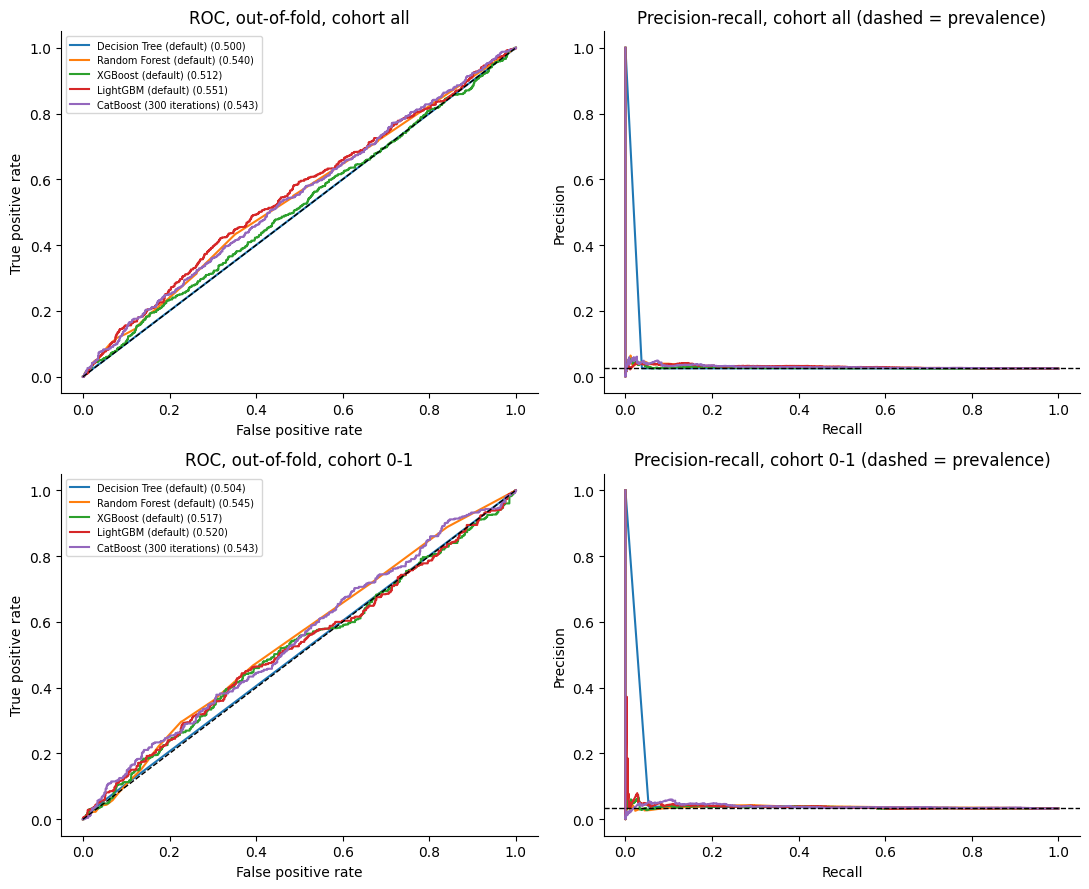

In [8]:
# ===== 7a. Default trees, PSU-grouped 5-fold, first seed only (diagnostic) =====
INTEGRITY_AUC_LIMIT = 0.85
def integrity_tripwire(auc_values, label):
    worst = float(np.nanmax(auc_values))
    if worst > INTEGRITY_AUC_LIMIT:
        raise AssertionError(f'INTEGRITY TRIPWIRE ({label}): out-of-fold weighted AUC {worst:.3f} > {INTEGRITY_AUC_LIMIT}. '
                             'Out-of-fold AUCs this high are not plausible for these predictors: look for leakage or in-sample scoring.')

def default_models(seed):
    m = {'Decision Tree (default)': DecisionTreeClassifier(random_state=seed),
         'Random Forest (default)': RandomForestClassifier(random_state=seed, n_jobs=N_JOBS)}
    if OPTIONAL['xgboost']: m['XGBoost (default)'] = XGBClassifier(random_state=seed, n_jobs=N_JOBS, eval_metric='logloss', verbosity=0)
    if OPTIONAL['lightgbm']: m['LightGBM (default)'] = LGBMClassifier(random_state=seed, n_jobs=N_JOBS, verbose=-1)
    if OPTIONAL['catboost']: m['CatBoost (300 iterations)'] = CatBoostClassifier(iterations=300, random_seed=seed, thread_count=N_JOBS, verbose=0, allow_writing_files=False)
    return m

seed0 = SEEDS[0]
_dpath = os.path.join(CACHE, f'default_{PROFILE}.pkl')
if RESUME and os.path.exists(_dpath):
    with open(_dpath, 'rb') as fh: default_rows, default_oof = pickle.load(fh)
else:
    default_rows, default_oof = [], {}
    for cohort in ['all', '0-1']:
        m_ = COHORT_MASK[cohort]; frame_ = XFRAME.loc[m_].reset_index(drop=True); feats_ = FEATURE_SETS[cohort]['FS0']
        X_ = frame_[feats_].to_numpy(float)                       # legacy encoding: integer codes, NaN left to the trees
        if _skv < (1, 4): X_ = np.nan_to_num(X_, nan=-1.0)       # sklearn < 1.4 trees cannot take NaN
        y_, w_, psu_ = Y[m_], W[m_], PSU[m_]
        oof_ = {k: np.full(len(y_), np.nan) for k in default_models(seed0)}
        for fold, (tr, te) in enumerate(StratifiedGroupKFold(N_OUTER, shuffle=True, random_state=seed0).split(X_, y_, psu_)):
            assert set(psu_[tr]).isdisjoint(psu_[te])
            for name, mdl in default_models(seed0).items():
                mdl.fit(X_[tr], y_[tr]); pt = mdl.predict_proba(X_[te])[:, 1]; ptr = mdl.predict_proba(X_[tr])[:, 1]
                oof_[name][te] = pt
                default_rows.append({'cohort': cohort, 'model': name, 'fold': fold, 'auc_w_train': safe_auc(y_[tr], ptr, w_[tr]), 'auc_w_test': safe_auc(y_[te], pt, w_[te]),
                                     'auc_u_train': safe_auc(y_[tr], ptr), 'auc_u_test': safe_auc(y_[te], pt)})
        for name, s_ in oof_.items():
            assert not np.isnan(s_).any()
        default_oof[cohort] = (y_, w_, oof_)
    with open(_dpath, 'wb') as fh: pickle.dump((default_rows, default_oof), fh)
default_tbl = pd.DataFrame(default_rows)
dsum = default_tbl.groupby(['cohort', 'model']).agg(train_auc_w=('auc_w_train', 'mean'), heldout_auc_w=('auc_w_test', 'mean'), heldout_auc_w_sd=('auc_w_test', 'std'),
                                                     train_auc_u=('auc_u_train', 'mean'), heldout_auc_u=('auc_u_test', 'mean')).reset_index()
dsum['apparent_optimism_gap'] = dsum['train_auc_w'] - dsum['heldout_auc_w']
pooled_def = []
for cohort, (y_, w_, oof_) in default_oof.items():
    for name, s_ in oof_.items():
        mt = metrics(y_, s_, w_, prob=True); pooled_def.append({'cohort': cohort, 'model': name, 'pooled_oof_auc_w': mt['auc_w'], 'pooled_oof_auc_u': mt['auc_u'], 'pooled_oof_ap_w': mt['ap_w'], 'prev_w': mt['prev_w']})
dsum = dsum.merge(pd.DataFrame(pooled_def), on=['cohort', 'model'])
dsum.round(4).to_csv(f'{OUT}/default_models_overfit.csv', index=False)
integrity_tripwire(dsum['pooled_oof_auc_w'], 'default trees')
print('Default (untuned) trees: training vs held-out AUC (apparent optimism gap = train - held-out; a diagnostic, not a generalisation estimate)')
print(dsum.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r_, cohort in enumerate(['all', '0-1']):
    y_, w_, oof_ = default_oof[cohort]
    for name, s_ in oof_.items():
        fpr, tpr, _ = roc_curve(y_, s_, sample_weight=w_); pr_, rc_, _ = precision_recall_curve(y_, s_, sample_weight=w_)
        axes[r_, 0].plot(fpr, tpr, label=f'{name} ({safe_auc(y_, s_, w_):.3f})'); axes[r_, 1].plot(rc_, pr_, label=name)
    axes[r_, 0].plot([0, 1], [0, 1], 'k--', lw=1); axes[r_, 0].set_title(f'ROC, out-of-fold, cohort {cohort}'); axes[r_, 0].legend(fontsize=7)
    axes[r_, 1].axhline(np.average(y_, weights=w_), color='k', ls='--', lw=1); axes[r_, 1].set_title(f'Precision-recall, cohort {cohort} (dashed = prevalence)')
    axes[r_, 0].set_xlabel('False positive rate'); axes[r_, 0].set_ylabel('True positive rate'); axes[r_, 1].set_xlabel('Recall'); axes[r_, 1].set_ylabel('Precision')
plt.tight_layout(); plt.savefig(f'{FIG}/default_trees_roc_pr.png', dpi=130); plt.show()

In [9]:
# ===== 7b. WARNING: the in-sample trap (do NOT report these numbers) =====
cohort = 'all'; y_, w_, oof_ = default_oof[cohort]
frame_ = XFRAME.copy(); X_ = frame_[FEATURE_SETS[cohort]['FS0']].to_numpy(float)
if _skv < (1, 4): X_ = np.nan_to_num(X_, nan=-1.0)
rf_full = RandomForestClassifier(random_state=seed0, n_jobs=N_JOBS).fit(X_, Y)           # fitted on ALL children ...
p_in = rf_full.predict_proba(X_)[:, 1]                                                   # ... and scored on the SAME children
thr_in = choose_threshold(Y, p_in, W); f_in = prf(Y, (p_in >= thr_in).astype(float), W)
oof_auc = safe_auc(y_, oof_['Random Forest (default)'], w_)
print('IN-SAMPLE default Random Forest (the trap):')
print(f'   weighted ROC-AUC = {safe_auc(Y, p_in, W):.4f}   weighted F1 = {f_in[2]:.3f}   F2 = {f_in[3]:.3f}   (threshold chosen on the same data)')
print(f'OUT-OF-FOLD default Random Forest, same children:   weighted ROC-AUC = {oof_auc:.4f}')
print('=> The perfect in-sample scores come from memorisation, not from signal. Only out-of-fold numbers are reported anywhere else in this notebook.')
del rf_full, p_in

IN-SAMPLE default Random Forest (the trap):
   weighted ROC-AUC = 1.0000   weighted F1 = 0.868   F2 = 0.943   (threshold chosen on the same data)
OUT-OF-FOLD default Random Forest, same children:   weighted ROC-AUC = 0.5401
=> The perfect in-sample scores come from memorisation, not from signal. Only out-of-fold numbers are reported anywhere else in this notebook.


## 8. Nested-CV experiments (the main run)

For every cohort x feature set the notebook produces, **per seed and per outer fold**, held-out predictions for:

* **Baselines (fixed, no tuning):** prevalence-only (dummy); logistic regression with age + sex (unweighted and survey-weighted); full logistic regression (unweighted and survey-weighted, C = 100, i.e. a very weak ridge for numerical stability); a stronger ridge logistic regression (C = 0.05, survey-weighted).
* **Tuned families:** elastic-net logistic regression, shallow decision tree, random forest, XGBoost, LightGBM, CatBoost (families that are not installed are skipped), each also with a Platt-calibrated variant whose calibrator is fitted on *inner* out-of-fold predictions of the training part only.
* **Simple ensemble:** mean predicted probability of the tuned EN-LR, RF, XGB, LGBM and CatBoost models (no extra fitting; decision trees are excluded because their probabilities are coarse).
* **Auxiliary-WHZ experiment:** a ridge model trained to predict continuous `whz2` **using training-fold targets only**, evaluated against held-out `severe_wasting`: (i) `-predicted WHZ` as a risk score, (ii) a mean + variance model giving P(WHZ < -3) under a normal tail, and (iii) a stacked logistic model on **cross-fitted** (inner-fold out-of-fold) auxiliary predictions plus age and sex. True WHZ is never an input of any classifier.

For tuned models and the ensemble, a **decision threshold** is also chosen (maximising weighted F2) on the *inner out-of-fold predictions of the training part* and then applied to the held-out fold, giving an honest operating point.

Per seed x fold the code records training and held-out weighted AUC and PR-AUC, the best inner-CV AUC, and the selected configuration, so the apparent and tuning optimism gaps can be computed in section 10. Finished blocks are cached, so an interrupted run resumes.

In [ ]:
# ===== 8a. Experiment plan and runner =====
M_DUMMY, M_AGESEX_U, M_AGESEX_W = 'Prevalence (dummy)', 'LR: age + sex (unweighted)', 'LR: age + sex (survey-weighted)'
M_FULL_U, M_FULL_W, M_RIDGE = 'LR: full (unweighted)', 'LR: full (survey-weighted)', 'LR: ridge C=0.05 (survey-weighted)'
M_ENS, M_AUX_MU, M_AUX_TAIL, M_AUX_STACK = 'Ensemble (mean prob)', 'Aux WHZ: ridge mean (-mu)', 'Aux WHZ: normal tail P(WHZ<-3)', 'Aux WHZ: stacked LR'
NONPROB = {M_AUX_MU}
FULL_FAMS, MID_FAMS = ['EN', 'DT', 'RF', 'XGB', 'LGBM', 'CB'], ['EN', 'XGB', 'LGBM', 'CB']
PLAN = {('all', 'FS0'): ['EN', 'XGB', 'LGBM'], ('all', 'FS1'): FULL_FAMS, ('all', 'FS2'): MID_FAMS,
        ('0-1', 'FS0'): ['EN', 'XGB', 'LGBM'], ('0-1', 'FS1'): FULL_FAMS, ('0-1', 'FS2'): MID_FAMS,
        ('2-4', 'FS0'): ['EN', 'LGBM'], ('2-4', 'FS1'): ['EN', 'XGB', 'LGBM']}      # 2-4: fewer events, reduced list

def aux_fit_predict(Xtr, ztr, wtr, Xte):
    sw = wtr / wtr.mean()
    m1 = Ridge(alpha=AUX_ALPHA).fit(Xtr, ztr, sample_weight=sw); e = ztr - m1.predict(Xtr)
    m2 = Ridge(alpha=AUX_ALPHA).fit(Xtr, np.log(e ** 2 + 1e-6) + 1.2704, sample_weight=sw)     # E[log chi2_1] = -1.2704
    return m1.predict(Xte), np.clip(np.exp(0.5 * m2.predict(Xte)), 0.3, 3.0)

def platt_apply(oof_in, ytr, wtr, p_target):
    m = LogisticRegression(C=1e6, max_iter=500).fit(logit_clip(oof_in).reshape(-1, 1), ytr, sample_weight=wtr)
    return m.predict_proba(logit_clip(p_target).reshape(-1, 1))[:, 1]

def compute_fold(cohort, fs, seed, fold, tr, te, frame, Xdf, feats, y, w, psu, z, fams):
    # Everything for ONE outer fold; returns plain dicts so it can be checkpointed.
    F = {'oof': {}, 'bin': {}, 'rows': [], 'tune': [], 'failed': []}
    ytr, yte, wtr, wte, ztr = y[tr], y[te], w[tr], w[te], z[tr]
    pre = build_preproc(feats, frame).fit(Xdf.iloc[tr]); Xtr, Xte = pre.transform(Xdf.iloc[tr]), pre.transform(Xdf.iloc[te])
    names = list(pre.get_feature_names_out()); age_cols = [i for i, nm in enumerate(names) if nm == 'female' or nm.startswith('ub2_')]
    inner_sets = []
    for itr, iva in StratifiedGroupKFold(N_INNER, shuffle=True, random_state=seed * 100 + fold).split(Xtr, ytr, psu[tr]):
        assert set(psu[tr][itr]).isdisjoint(psu[tr][iva]), 'PSU crosses an inner fold boundary'
        pi = build_preproc(feats, frame).fit(Xdf.iloc[tr].iloc[itr])
        inner_sets.append((itr, iva, pi.transform(Xdf.iloc[tr].iloc[itr]), pi.transform(Xdf.iloc[tr].iloc[iva])))

    def record(name, p_te, p_tr=None, inner_auc=np.nan, inner_ap=np.nan, params=None, thr=None):
        F['oof'][name] = p_te
        if thr is not None: F['bin'][name] = (p_te >= thr).astype(float)
        F['rows'].append({'cohort': cohort, 'fs': fs, 'model': name, 'seed': seed, 'fold': fold, 'n_test': len(te), 'events_test': int(yte.sum()),
                          'auc_w_test': safe_auc(yte, p_te, wte), 'auc_u_test': safe_auc(yte, p_te), 'ap_w_test': safe_ap(yte, p_te, wte), 'ap_u_test': safe_ap(yte, p_te),
                          'auc_w_train': safe_auc(ytr, p_tr, wtr) if p_tr is not None else np.nan, 'ap_w_train': safe_ap(ytr, p_tr, wtr) if p_tr is not None else np.nan,
                          'inner_auc_w': inner_auc, 'inner_ap_w': inner_ap, 'threshold': thr if thr is not None else np.nan,
                          'params': json.dumps(params, default=float) if params is not None else ''})

    # --- baselines (no tuning) ---
    p0 = float(ytr.mean()); record(M_DUMMY, np.full(len(te), p0), np.full(len(tr), p0))
    allc = list(range(Xtr.shape[1]))
    for nm, cols, scheme, C in [(M_AGESEX_U, age_cols, 'none', 100.0), (M_AGESEX_W, age_cols, 'survey', 100.0), (M_FULL_U, allc, 'none', 100.0),
                                (M_FULL_W, allc, 'survey', 100.0), (M_RIDGE, allc, 'survey', 0.05)]:
        lr = LogisticRegression(C=C, max_iter=2000).fit(Xtr[:, cols], ytr, sample_weight=make_sw(scheme, ytr, wtr))
        record(nm, lr.predict_proba(Xte[:, cols])[:, 1], lr.predict_proba(Xtr[:, cols])[:, 1])

    # --- tuned families (custom weighted inner search) ---
    tuned = {}
    for fi, fam in enumerate(fams):
        try:
            (sc, cfg, oof_in, cid_), recs = tune_family(fam, inner_sets, ytr, wtr, seed, seed * 1000 + fold * 10 + fi)
            est = fit_est(fam, cfg, Xtr, ytr, wtr, seed); p_te, p_tr = predict_p(est, Xte), predict_p(est, Xtr)
        except Exception as e:
            F['failed'].append((fam, seed, fold, repr(e)[:200])); print(f'   !! {FAMILY_LABEL[fam]} failed (seed {seed}, fold {fold}): {repr(e)[:120]}'); continue
        inner_ap = safe_ap(ytr, oof_in, wtr); thr = choose_threshold(ytr, oof_in, wtr)
        for r in recs: r.update(cohort=cohort, fs=fs, seed=seed, fold=fold)
        F['tune'] += recs; tuned[fam] = dict(p_te=p_te, p_tr=p_tr, oof_in=oof_in, sc=sc, cfg=cfg, ap=inner_ap)
        record(FAMILY_LABEL[fam], p_te, p_tr, sc, inner_ap, cfg, thr)
        record(FAMILY_LABEL[fam] + ' [Platt]', platt_apply(oof_in, ytr, wtr, p_te), platt_apply(oof_in, ytr, wtr, p_tr), sc, inner_ap, cfg, None)

    # --- simple ensemble ---
    comps = [f for f in tuned if f != 'DT']
    if len(comps) >= 2:
        p_te = np.mean([tuned[f]['p_te'] for f in comps], axis=0); p_tr = np.mean([tuned[f]['p_tr'] for f in comps], axis=0)
        oof_in = np.mean([tuned[f]['oof_in'] for f in comps], axis=0)
        sc = float(np.nanmean([safe_auc(ytr[iva], oof_in[iva], wtr[iva]) for _, iva, _, _ in inner_sets]))
        record(M_ENS, p_te, p_tr, sc, safe_ap(ytr, oof_in, wtr), {'components': comps}, choose_threshold(ytr, oof_in, wtr))
        record(M_ENS + ' [Platt]', platt_apply(oof_in, ytr, wtr, p_te), platt_apply(oof_in, ytr, wtr, p_tr), sc, safe_ap(ytr, oof_in, wtr), {'components': comps}, None)

    # --- auxiliary WHZ experiment (training-fold targets only; stacking is cross-fitted) ---
    mu_te, sg_te = aux_fit_predict(Xtr, ztr, wtr, Xte)
    record(M_AUX_MU, -mu_te); record(M_AUX_TAIL, norm.cdf((-3 - mu_te) / sg_te))
    mu_o, sg_o = np.zeros(len(tr)), np.zeros(len(tr))
    for itr, iva, Xi_tr, Xi_va in inner_sets:
        mu_o[iva], sg_o[iva] = aux_fit_predict(Xi_tr, ztr[itr], wtr[itr], Xi_va)
    sf = lambda Xb, mu, sg: np.column_stack([mu, np.log(sg), logit_clip(norm.cdf((-3 - mu) / sg)), Xb[:, age_cols]])
    S_tr, S_te = sf(Xtr, mu_o, sg_o), sf(Xte, mu_te, sg_te); ss = StandardScaler().fit(S_tr)
    st = LogisticRegression(C=0.5, max_iter=1000).fit(ss.transform(S_tr), ytr, sample_weight=make_sw('survey', ytr, wtr))
    record(M_AUX_STACK, st.predict_proba(ss.transform(S_te))[:, 1], st.predict_proba(ss.transform(S_tr))[:, 1])
    return F

def run_experiment(cohort, fs):
    path = os.path.join(CACHE, f'{PROFILE}_{cohort}_{fs}.pkl')
    if RESUME and os.path.exists(path):
        with open(path, 'rb') as fh: return pickle.load(fh)
    t0 = time.time(); m = COHORT_MASK[cohort]; frame = XFRAME.loc[m].reset_index(drop=True)
    y, w, psu, z, cid = Y[m], W[m], PSU[m], Z_AUX[m], df['child_id'].to_numpy()[m]
    feats = FEATURE_SETS[cohort][fs]; Xdf = frame[feats]; n = len(y); fams = [f for f in PLAN[(cohort, fs)] if family_available(f)]
    oof, oofbin, fold_rows, tune_rows, failed = {}, {}, [], [], []
    for seed in SEEDS:
        seen = np.zeros(n, int)
        for fold, (tr, te) in enumerate(StratifiedGroupKFold(N_OUTER, shuffle=True, random_state=seed).split(Xdf, y, psu)):
            assert set(psu[tr]).isdisjoint(psu[te]), 'PSU crosses an outer fold boundary'
            seen[te] += 1
            fpath = os.path.join(CACHE, f'fold_{PROFILE}_{cohort}_{fs}_{seed}_{fold}.pkl')          # checkpoint per outer fold
            if RESUME and os.path.exists(fpath):
                with open(fpath, 'rb') as fh: F = pickle.load(fh)
            else:
                F = compute_fold(cohort, fs, seed, fold, tr, te, frame, Xdf, feats, y, w, psu, z, fams)
                with open(fpath, 'wb') as fh: pickle.dump(F, fh)
            for name, p in F['oof'].items(): oof.setdefault(name, {}).setdefault(seed, np.full(n, np.nan))[te] = p
            for name, b_ in F['bin'].items(): oofbin.setdefault(name, {}).setdefault(seed, np.full(n, np.nan))[te] = b_
            fold_rows += F['rows']; tune_rows += F['tune']; failed += F['failed']
            print(f'      [{cohort} {fs}] seed {seed} fold {fold} done ({time.time() - t0:.0f}s)', flush=True)
        assert (seen == 1).all(), 'Some child did not receive exactly one out-of-fold prediction'
    for name, d_ in oof.items():
        for seed, s_ in d_.items(): assert not np.isnan(s_).any(), f'{name} seed {seed}: missing OOF predictions'
    res = dict(cohort=cohort, fs=fs, oof=oof, oofbin=oofbin, folds=pd.DataFrame(fold_rows), tuning=pd.DataFrame(tune_rows), failed=failed,
               y=y, w=w, psu=psu, child_id=cid, features=feats, runtime_s=time.time() - t0)
    with open(path, 'wb') as fh: pickle.dump(res, fh)
    return res

RUN_KEYS = [k for k in PLAN if not (k[1] == 'FS2' and not HAVE_REVISED)]
RES = {}
for k_ in RUN_KEYS:
    print(f'\n>>> Running {k_} with families {[f for f in PLAN[k_] if family_available(f)]}', flush=True)
    RES[k_] = run_experiment(*k_)
    print(f'>>> {k_} finished: {len(RES[k_]["oof"])} model variants, {RES[k_]["runtime_s"]:.0f}s, failures: {len(RES[k_]["failed"])}', flush=True)
print(f'\nAll experiment blocks finished. Elapsed since start: {(time.time() - T_START) / 60:.1f} min')


>>> Running ('all', 'FS0') with families ['EN', 'XGB', 'LGBM']
      [all FS0] seed 42 fold 0 done (8s)
      [all FS0] seed 42 fold 1 done (13s)
      [all FS0] seed 42 fold 2 done (21s)
      [all FS0] seed 42 fold 3 done (29s)
      [all FS0] seed 42 fold 4 done (40s)
      [all FS0] seed 43 fold 0 done (48s)
      [all FS0] seed 43 fold 1 done (58s)
      [all FS0] seed 43 fold 2 done (68s)
      [all FS0] seed 43 fold 3 done (76s)
      [all FS0] seed 43 fold 4 done (86s)
      [all FS0] seed 44 fold 0 done (93s)
      [all FS0] seed 44 fold 1 done (107s)
      [all FS0] seed 44 fold 2 done (111s)
      [all FS0] seed 44 fold 3 done (115s)
      [all FS0] seed 44 fold 4 done (128s)
>>> ('all', 'FS0') finished: 17 model variants, 128s, failures: 0

>>> Running ('all', 'FS1') with families ['EN', 'DT', 'RF', 'XGB', 'LGBM', 'CB']


In [ ]:
# ===== 8b. Save tuning results and out-of-fold predictions =====
tuning_all = pd.concat([R['tuning'] for R in RES.values()], ignore_index=True)
tuning_all.to_csv(f'{OUT}/tuning_results.csv', index=False)
for (cohort, fs), R in RES.items():
    parts = []
    for seed in SEEDS:
        d_ = pd.DataFrame({'child_id': R['child_id'], 'psu': R['psu'], 'y': R['y'], 'w': R['w'], 'seed': seed})
        for m_, dd in R['oof'].items(): d_[m_] = np.round(dd[seed], 5)
        parts.append(d_)
    pd.concat(parts, ignore_index=True).to_csv(f'{OUT}/oof_predictions_{cohort}_{fs}.csv.gz', index=False, compression='gzip')
print(f'Saved tuning_results.csv ({len(tuning_all)} rows) and {len(RES)} out-of-fold prediction files (child_id, PSU, outcome, weight, one column per model, per seed).')

# Class-weighting comparison inside the tuned searches (descriptive): does balancing or survey weighting win on inner weighted AUC?
tuning_all['scheme'] = tuning_all['params'].map(lambda s: json.loads(s).get('scheme'))
sch = (tuning_all.groupby(['cohort', 'fs', 'family', 'scheme'])
       .agg(configs=('inner_auc_w_mean', 'size'), mean_inner_auc_w=('inner_auc_w_mean', 'mean'), times_selected=('selected', 'sum')).reset_index())
sch['selected_share_%'] = 100 * sch['times_selected'] / sch.groupby(['cohort', 'fs', 'family'])['times_selected'].transform('sum')
sch.to_csv(f'{OUT}/class_weighting_comparison.csv', index=False)
print('\nFitting-scheme comparison inside the inner searches (FS1; none = ordinary, survey = survey-weighted, balanced = case up-weighting):')
print(sch[sch.fs == 'FS1'].round(4).to_string(index=False))

Saved tuning_results.csv (1860 rows) and 8 out-of-fold prediction files (child_id, PSU, outcome, weight, one column per model, per seed).

Fitting-scheme comparison inside the inner searches (FS1; none = ordinary, survey = survey-weighted, balanced = case up-weighting):
cohort  fs family   scheme  configs  mean_inner_auc_w  times_selected  selected_share_%
   0-1 FS1     CB balanced       12            0.5646               3           20.0000
   0-1 FS1     CB     none       18            0.5778               4           26.6667
   0-1 FS1     CB   survey       30            0.5729               8           53.3333
   0-1 FS1     DT balanced       18            0.5529               5           33.3333
   0-1 FS1     DT     none       12            0.5484               4           26.6667
   0-1 FS1     DT   survey       30            0.5369               6           40.0000
   0-1 FS1     EN balanced       15            0.5761               1            6.6667
   0-1 FS1     EN     non

## 9. Pooled out-of-fold results

Every number below comes from **held-out predictions only**: each child is predicted by models that never saw any child from the same PSU. "Pooled" means all out-of-fold predictions of one seed are put together (so fold-level calibration differences are included); the table reports the mean and SD across seeds. Both survey-weighted (`_w`, uses `chweight`) and unweighted (`_u`) metrics are reported; the weighted metrics are ordinary *predictive-weighted* metrics and are **not** design-based inference. PR-AUC is always read against the outcome prevalence (`prev`). The prevalence-only dummy gives a pooled AUC slightly below 0.5 purely because its constant differs by fold.

In [ ]:
# ===== 9. Pooled metrics, fold-level metrics, paired differences =====
pooled_rows = []
for (cohort, fs), R in RES.items():
    for model, d_ in R['oof'].items():
        for seed, s_ in d_.items():
            pooled_rows.append({'cohort': cohort, 'fs': fs, 'model': model, 'seed': seed, **metrics(R['y'], s_, R['w'], prob=(model not in NONPROB))})
pooled = pd.DataFrame(pooled_rows)
integrity_tripwire(pooled['auc_w'], 'pooled out-of-fold results')
pooled.to_csv(f'{OUT}/pooled_metrics_by_seed.csv', index=False)

AGG = ['auc_w', 'auc_u', 'ap_w', 'ap_u', 'prev_w', 'prev_u', 'brier_w', 'brier_u', 'cal_int_w', 'cal_slope_w', 'cal_int_u', 'cal_slope_u', 'top10_w', 'top10_u']
gq = pooled.groupby(['cohort', 'fs', 'model'])
tbl = gq[AGG].mean().add_suffix('_mean').join(gq[AGG].std().add_suffix('_sd')).reset_index()

folds_all = pd.concat([R['folds'] for R in RES.values()], ignore_index=True)
folds_all.to_csv(f'{OUT}/fold_metrics.csv', index=False)
fl = folds_all.groupby(['cohort', 'fs', 'model']).agg(fold_auc_w_mean=('auc_w_test', 'mean'), fold_auc_w_sd=('auc_w_test', 'std'),
                                                      fold_auc_u_mean=('auc_u_test', 'mean'), fold_auc_u_sd=('auc_u_test', 'std')).reset_index()
tbl = tbl.merge(fl, on=['cohort', 'fs', 'model'])

# paired differences on identical held-out children, per seed
piv_w = pooled.pivot_table(index=['cohort', 'fs', 'seed'], columns='model', values='auc_w')
piv_u = pooled.pivot_table(index=['cohort', 'fs', 'seed'], columns='model', values='auc_u')
drows = []
for (cohort, fs), R in RES.items():
    for model in R['oof']:
        row = {'cohort': cohort, 'fs': fs, 'model': model}
        for tag, piv in (('w', piv_w), ('u', piv_u)):
            for refname, ref in (('age_sex', REF_AGE), ('full_w', REF_FULL)):
                dd = (piv.loc[(cohort, fs), model] - piv.loc[(cohort, fs), ref]).values
                row[f'diff_{refname}_auc_{tag}_mean'] = dd.mean(); row[f'diff_{refname}_auc_{tag}_min'] = dd.min(); row[f'diff_{refname}_auc_{tag}_max'] = dd.max()
                row[f'diff_{refname}_auc_{tag}_seeds_positive'] = int((dd > 0).sum())
        drows.append(row)
tbl = tbl.merge(pd.DataFrame(drows), on=['cohort', 'fs', 'model'])
tbl['n_seeds'] = len(SEEDS)

SHOW = ['model', 'auc_w_mean', 'auc_w_sd', 'auc_u_mean', 'ap_w_mean', 'prev_w_mean', 'brier_w_mean', 'cal_slope_w_mean', 'top10_w_mean', 'diff_age_sex_auc_w_mean', 'diff_age_sex_auc_w_seeds_positive']
with pd.option_context('display.width', 250, 'display.max_colwidth', 40):
    for (cohort, fs), R in RES.items():
        t_ = tbl[(tbl.cohort == cohort) & (tbl.fs == fs) & ~tbl.model.str.contains('Platt')].sort_values('auc_w_mean', ascending=False)
        print(f'\n=== cohort {cohort} | {fs} | n={len(R["y"]):,} | cases={int(R["y"].sum())} | seeds={len(SEEDS)} | weighted prevalence={t_.prev_w_mean.iloc[0]:.4f}')
        print(t_[SHOW].round(4).to_string(index=False))


=== cohort all | FS0 | n=22,311 | cases=552 | seeds=3 | weighted prevalence=0.0252
                             model  auc_w_mean  auc_w_sd  auc_u_mean  ap_w_mean  prev_w_mean  brier_w_mean  cal_slope_w_mean  top10_w_mean  diff_age_sex_auc_w_mean  diff_age_sex_auc_w_seeds_positive
               Aux WHZ: stacked LR      0.5876    0.0038      0.5870     0.0349       0.0252        0.0245            0.9297        0.1829                   0.0039                                  3
LR: ridge C=0.05 (survey-weighted)      0.5843    0.0016      0.5827     0.0360       0.0252        0.0245            0.7222        0.1677                   0.0006                                  2
        LR: age + sex (unweighted)      0.5837    0.0018      0.5820     0.0346       0.0252        0.0245            0.9276        0.1884                   0.0000                                  0
             LR: full (unweighted)      0.5837    0.0017      0.5832     0.0361       0.0252        0.0245            0.

## 10. Overfitting gaps

For every model, seed and outer fold:

* **Apparent optimism gap** = weighted AUC of the fitted outer-training model on its own training children minus its held-out AUC. This is a diagnostic of memorisation, **not** an estimate of generalisation error, and training scores are never used as performance.
* **Tuning optimism gap** = best inner-CV AUC (the score used to pick the configuration) minus the outer held-out AUC; it measures how much selecting the best of several configurations inflates the apparent score.
* The same two gaps are computed for PR-AUC (inner PR-AUC is the weighted average precision of the pooled inner out-of-fold predictions).

Flags: training AUC > 0.95 ("suspiciously perfect"), apparent gap > 0.15, tuning gap > 0.05, and SD across seeds > 0.01 ("unstable").

Overfitting gaps, mean over folds then seeds (FS1 shown; all feature sets are in outputs/overfitting_gaps.csv)
cohort                              model  auc_w_train_mean  auc_w_test_mean  apparent_gap_auc_mean  inner_auc_w_mean  tuning_gap_auc_mean  apparent_gap_ap_mean  tuning_gap_ap_mean  auc_w_test_sd_across_seeds
   0-1                Aux WHZ: stacked LR             0.583            0.564                  0.019               NaN                  NaN                 0.004                 NaN                       0.003
   0-1               Ensemble (mean prob)             0.733            0.593                  0.141             0.592               -0.001                 0.067              -0.010                       0.010
   0-1    LR: age + sex (survey-weighted)             0.562            0.551                  0.010               NaN                  NaN                 0.000                 NaN                       0.004
   0-1         LR: age + sex (unweighted)            

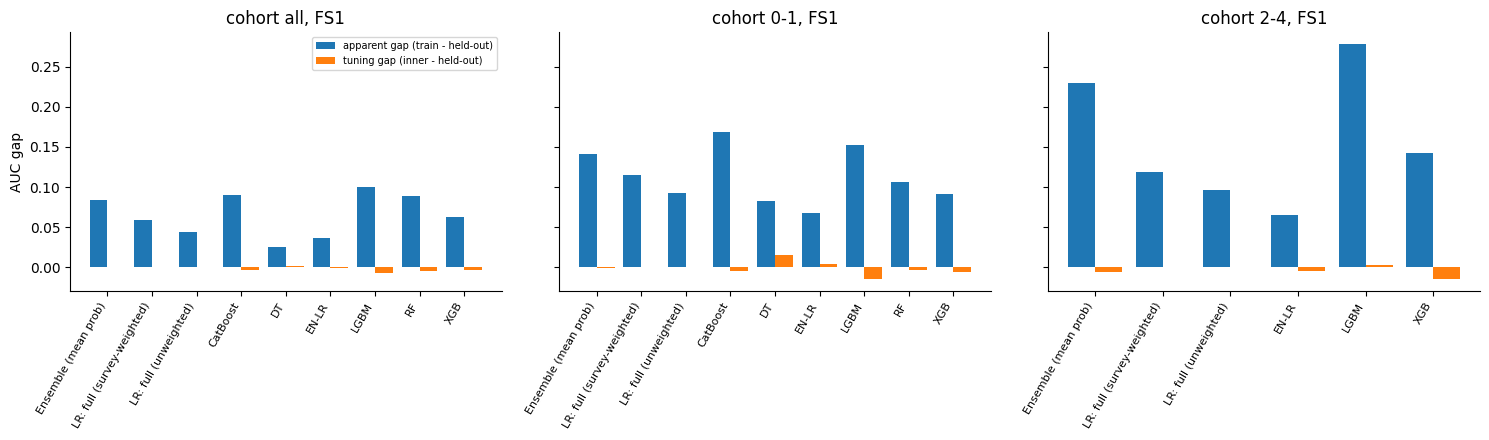

In [ ]:
# ===== 10. Overfitting gaps =====
folds_all['apparent_gap_auc'] = folds_all['auc_w_train'] - folds_all['auc_w_test']
folds_all['tuning_gap_auc'] = folds_all['inner_auc_w'] - folds_all['auc_w_test']
folds_all['apparent_gap_ap'] = folds_all['ap_w_train'] - folds_all['ap_w_test']
folds_all['tuning_gap_ap'] = folds_all['inner_ap_w'] - folds_all['ap_w_test']
GAPC = ['auc_w_train', 'auc_w_test', 'apparent_gap_auc', 'inner_auc_w', 'tuning_gap_auc', 'ap_w_train', 'ap_w_test', 'apparent_gap_ap', 'inner_ap_w', 'tuning_gap_ap']
per_seed = folds_all.groupby(['cohort', 'fs', 'model', 'seed'])[GAPC].mean()
gaps = per_seed.groupby(level=[0, 1, 2]).mean().add_suffix('_mean').join(per_seed.groupby(level=[0, 1, 2]).std().add_suffix('_sd_across_seeds'))
gaps = gaps.join(folds_all.groupby(['cohort', 'fs', 'model'])[['apparent_gap_auc', 'tuning_gap_auc']].std().add_suffix('_sd_across_folds')).reset_index()
gaps['flag_perfect_train'] = gaps['auc_w_train_mean'] > 0.95
gaps['flag_large_apparent_gap'] = gaps['apparent_gap_auc_mean'] > 0.15
gaps['flag_large_tuning_gap'] = gaps['tuning_gap_auc_mean'] > 0.05
gaps['flag_seed_unstable'] = gaps['auc_w_test_sd_across_seeds'] > 0.01
gaps.to_csv(f'{OUT}/overfitting_gaps.csv', index=False)
G = gaps[~gaps.model.str.contains('Platt') & ~gaps.model.isin([M_DUMMY, M_AUX_MU, M_AUX_TAIL])]
with pd.option_context('display.width', 250, 'display.max_colwidth', 36):
    print('Overfitting gaps, mean over folds then seeds (FS1 shown; all feature sets are in outputs/overfitting_gaps.csv)')
    print(G[G.fs == 'FS1'][['cohort', 'model', 'auc_w_train_mean', 'auc_w_test_mean', 'apparent_gap_auc_mean', 'inner_auc_w_mean', 'tuning_gap_auc_mean',
                            'apparent_gap_ap_mean', 'tuning_gap_ap_mean', 'auc_w_test_sd_across_seeds']].round(3).to_string(index=False))
    fl_ = G[G.flag_perfect_train | G.flag_large_apparent_gap | G.flag_large_tuning_gap | G.flag_seed_unstable]
    print('\nFlagged (perfect training / large apparent gap / large tuning gap / unstable across seeds):')
    print(fl_[['cohort', 'fs', 'model', 'auc_w_train_mean', 'apparent_gap_auc_mean', 'tuning_gap_auc_mean', 'auc_w_test_sd_across_seeds']].round(3).to_string(index=False) if len(fl_) else '(none)')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, cohort in zip(axes, ['all', '0-1', '2-4']):
    g_ = G[(G.cohort == cohort) & (G.fs == 'FS1') & G.model.str.startswith(('Tuned', 'LR: full', 'Ensemble'))]
    x_ = np.arange(len(g_)); ax.bar(x_ - 0.2, g_['apparent_gap_auc_mean'], 0.4, label='apparent gap (train - held-out)'); ax.bar(x_ + 0.2, g_['tuning_gap_auc_mean'].fillna(0), 0.4, label='tuning gap (inner - held-out)')
    ax.set_xticks(x_); ax.set_xticklabels([m.replace('Tuned ', '') for m in g_['model']], rotation=60, ha='right', fontsize=8); ax.set_title(f'cohort {cohort}, FS1')
axes[0].set_ylabel('AUC gap'); axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f'{FIG}/overfitting_gaps_fs1.png', dpi=130); plt.show()

## 11. Stability across seeds

A model that wins in one fold partition but not in others is not a reproducible improvement. The table shows the pooled weighted AUC for each seed and the paired difference versus the age + sex and full survey-weighted logistic baselines; the plot shows how the headline models move between seeds.

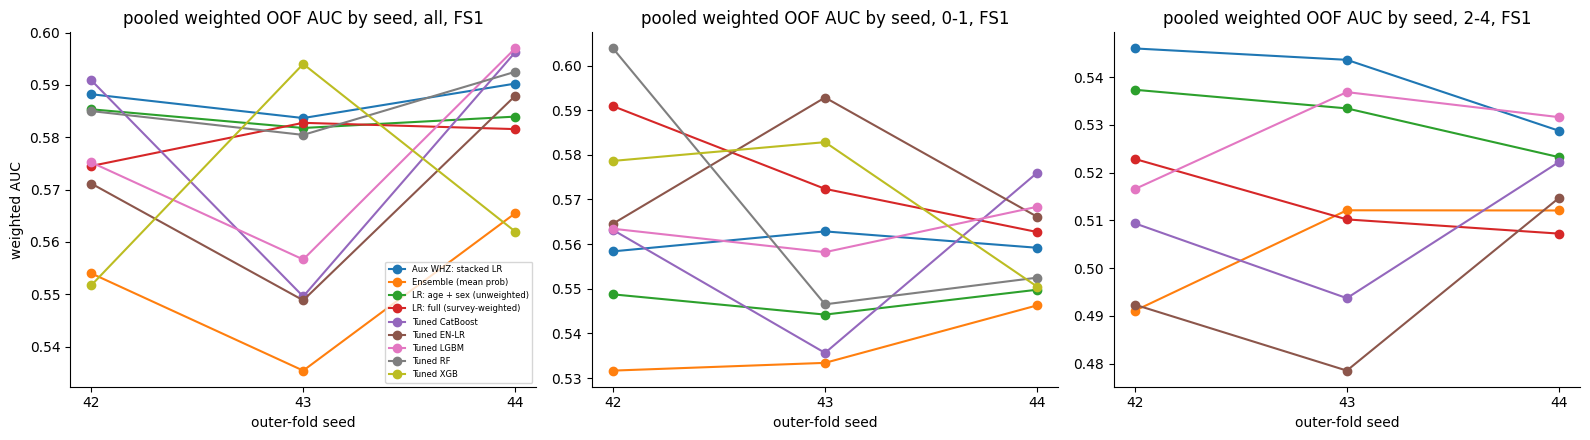

Largest seed-to-seed AUC ranges (FS1):
cohort               model  auc_w_range_across_seeds
   2-4  Tuned LGBM [Platt]                    0.0672
   0-1            Tuned RF                    0.0573
   2-4 Tuned EN-LR [Platt]                    0.0478
   all      Tuned CatBoost                    0.0467
   all           Tuned XGB                    0.0423
   all          Tuned LGBM                    0.0403
   0-1      Tuned CatBoost                    0.0403
   all         Tuned EN-LR                    0.0391


In [ ]:
# ===== 11. Seed stability =====
seed_cmp = pooled.pivot_table(index=['cohort', 'fs', 'model'], columns='seed', values='auc_w')
seed_cmp.columns = [f'auc_w_seed_{c}' for c in seed_cmp.columns]
seed_cmp['auc_w_range_across_seeds'] = seed_cmp.max(axis=1) - seed_cmp.min(axis=1)
seed_cmp = seed_cmp.reset_index().merge(tbl[['cohort', 'fs', 'model', 'diff_age_sex_auc_w_mean', 'diff_age_sex_auc_w_seeds_positive', 'diff_full_w_auc_w_mean', 'diff_full_w_auc_w_seeds_positive']], on=['cohort', 'fs', 'model'])
seed_cmp.to_csv(f'{OUT}/seed_comparison.csv', index=False)
key_models = [REF_AGE, REF_FULL, 'Tuned EN-LR', 'Tuned LGBM', 'Tuned XGB', 'Tuned RF', 'Tuned CatBoost', M_ENS, M_AUX_STACK]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, cohort in zip(axes, ['all', '0-1', '2-4']):
    s_ = seed_cmp[(seed_cmp.cohort == cohort) & (seed_cmp.fs == 'FS1') & seed_cmp.model.isin(key_models)]
    cols_ = [c for c in s_.columns if c.startswith('auc_w_seed_')]
    for _, r_ in s_.iterrows(): ax.plot(range(len(cols_)), r_[cols_].astype(float).values, marker='o', label=r_['model'])
    ax.set_xticks(range(len(cols_))); ax.set_xticklabels([c.split('_')[-1] for c in cols_]); ax.set_xlabel('outer-fold seed'); ax.set_title(f'pooled weighted OOF AUC by seed, {cohort}, FS1')
axes[0].set_ylabel('weighted AUC'); axes[0].legend(fontsize=6); plt.tight_layout(); plt.savefig(f'{FIG}/seed_stability_fs1.png', dpi=130); plt.show()
with pd.option_context('display.width', 250, 'display.max_colwidth', 36):
    print('Largest seed-to-seed AUC ranges (FS1):')
    print(seed_cmp[seed_cmp.fs == 'FS1'].sort_values('auc_w_range_across_seeds', ascending=False).head(8)[['cohort', 'model', 'auc_w_range_across_seeds']].round(4).to_string(index=False))

## 12. PSU cluster-bootstrap confidence intervals and paired differences

Whole PSUs are resampled with replacement (`N_BOOT` replicates). In each replicate the **same** resampled PSUs are used for every model and every seed, the AUC is computed on the held-out predictions with each PSU weighted by its resampling multiplicity, and then averaged over seeds; paired differences are computed inside the same replicate. Intervals are 2.5-97.5 percentiles. Platt-calibrated variants are omitted here because within a fold they rank children exactly like the uncalibrated model. These are predictive-weighted cluster-bootstrap intervals, **not** a complex-survey design-based inference.

In [ ]:
# ===== 12. PSU cluster bootstrap (weighted and unweighted AUC; CIs for AUC and paired differences) =====
def cluster_bootstrap(R, n_boot, rng_seed):
    y, w, psu = R['y'].astype(float), R['w'], R['psu']; upsu, pidx = np.unique(psu, return_inverse=True)
    models = [m for m in R['oof'] if '[Platt]' not in m]; seeds = sorted(next(iter(R['oof'].values())))
    fast = {(m, s): FastAUC(R['oof'][m][s]) for m in models for s in seeds}
    obs = {(m, t): np.mean([fast[(m, s)](y, w if t == 'w' else np.ones_like(w)) for s in seeds]) for m in models for t in ('w', 'u')}
    rng = np.random.RandomState(rng_seed); reps = {(m, t): [] for m in models for t in ('w', 'u')}; ok = 0
    for b in range(n_boot):
        mult = np.bincount(rng.randint(0, len(upsu), len(upsu)), minlength=len(upsu))[pidx].astype(float)
        vals = {}
        for t, ww in (('w', w * mult), ('u', mult)):
            for m in models: vals[(m, t)] = np.mean([fast[(m, s)](y, ww) for s in seeds])
        if any(np.isnan(v) for v in vals.values()): continue
        ok += 1
        for k_, v_ in vals.items(): reps[k_].append(v_)
    reps = {k_: np.array(v_) for k_, v_ in reps.items()}
    rows = []
    for m in models:
        for t in ('w', 'u'):
            r_ = {'model': m, 'weighted': t == 'w', 'auc_seed_mean': obs[(m, t)], 'auc_ci_lo': np.percentile(reps[(m, t)], 2.5), 'auc_ci_hi': np.percentile(reps[(m, t)], 97.5), 'n_boot_success': ok}
            for refname, ref in (('age_sex', REF_AGE), ('full_w', REF_FULL)):
                d_ = reps[(m, t)] - reps[(ref, t)]
                r_[f'diff_{refname}'] = obs[(m, t)] - obs[(ref, t)]; r_[f'diff_{refname}_ci_lo'] = np.percentile(d_, 2.5); r_[f'diff_{refname}_ci_hi'] = np.percentile(d_, 97.5)
            rows.append(r_)
    return pd.DataFrame(rows)

boot_parts = []
for (cohort, fs), R in RES.items():
    t0_ = time.time(); b_ = cluster_bootstrap(R, N_BOOT, BOOT_SEED); b_.insert(0, 'fs', fs); b_.insert(0, 'cohort', cohort); boot_parts.append(b_)
    print(f'bootstrap {cohort} {fs}: {b_.n_boot_success.iloc[0]}/{N_BOOT} successful replicates ({time.time() - t0_:.0f}s)', flush=True)
boot = pd.concat(boot_parts, ignore_index=True); boot.to_csv(f'{OUT}/bootstrap_results.csv', index=False)
assert (boot.n_boot_success >= min(300, N_BOOT)).all() or PROFILE == 'smoke', 'Fewer than 300 successful bootstrap replicates'
bw = boot[boot.weighted]
with pd.option_context('display.width', 250, 'display.max_colwidth', 36):
    for (cohort, fs), R in RES.items():
        if fs != 'FS1': continue
        t_ = bw[(bw.cohort == cohort) & (bw.fs == fs)].sort_values('auc_seed_mean', ascending=False)
        print(f'\n=== {cohort} | {fs}: weighted AUC (seed-mean) with PSU-bootstrap 95% CI and paired difference vs baselines')
        print(t_[['model', 'auc_seed_mean', 'auc_ci_lo', 'auc_ci_hi', 'diff_age_sex', 'diff_age_sex_ci_lo', 'diff_age_sex_ci_hi', 'diff_full_w', 'diff_full_w_ci_lo', 'diff_full_w_ci_hi']].round(4).to_string(index=False))
tbl = tbl.merge(bw[['cohort', 'fs', 'model', 'auc_ci_lo', 'auc_ci_hi', 'diff_age_sex', 'diff_age_sex_ci_lo', 'diff_age_sex_ci_hi', 'diff_full_w', 'diff_full_w_ci_lo', 'diff_full_w_ci_hi']]
                .rename(columns={'auc_ci_lo': 'boot_auc_w_ci_lo', 'auc_ci_hi': 'boot_auc_w_ci_hi'}), on=['cohort', 'fs', 'model'], how='left')

bootstrap all FS0: 300/300 successful replicates (11s)


bootstrap all FS1: 300/300 successful replicates (12s)


bootstrap all FS2: 300/300 successful replicates (12s)


bootstrap 0-1 FS0: 300/300 successful replicates (4s)


bootstrap 0-1 FS1: 300/300 successful replicates (5s)


bootstrap 0-1 FS2: 300/300 successful replicates (5s)


bootstrap 2-4 FS0: 300/300 successful replicates (6s)


bootstrap 2-4 FS1: 300/300 successful replicates (7s)



=== all | FS1: weighted AUC (seed-mean) with PSU-bootstrap 95% CI and paired difference vs baselines
                             model  auc_seed_mean  auc_ci_lo  auc_ci_hi  diff_age_sex  diff_age_sex_ci_lo  diff_age_sex_ci_hi  diff_full_w  diff_full_w_ci_lo  diff_full_w_ci_hi
               Aux WHZ: stacked LR         0.5874     0.5598     0.6160        0.0037             -0.0081              0.0162       0.0078            -0.0092             0.0246
                          Tuned RF         0.5860     0.5612     0.6103        0.0023             -0.0191              0.0236       0.0064            -0.0108             0.0244
        LR: age + sex (unweighted)         0.5837     0.5566     0.6105        0.0000              0.0000              0.0000       0.0041            -0.0144             0.0247
   LR: age + sex (survey-weighted)         0.5808     0.5537     0.6073       -0.0029             -0.0095              0.0035       0.0012            -0.0172             0.0219
             

## 13. Calibration and operating points

* **Calibration** is assessed on pooled out-of-fold probabilities (seed 1): reliability curves plus the calibration slope/intercept reported above. Platt variants use a calibrator fitted on the *inner* out-of-fold predictions of the training part only and are then applied to held-out children.
* **Operating points.** The threshold of each tuned model is chosen on the inner out-of-fold predictions of the training part (maximising weighted F2) and applied to the held-out fold. Because only about 2.5% of children are cases, even a good ranking model yields low precision and F-scores; these are reported to show the real trade-off, not to claim accuracy.

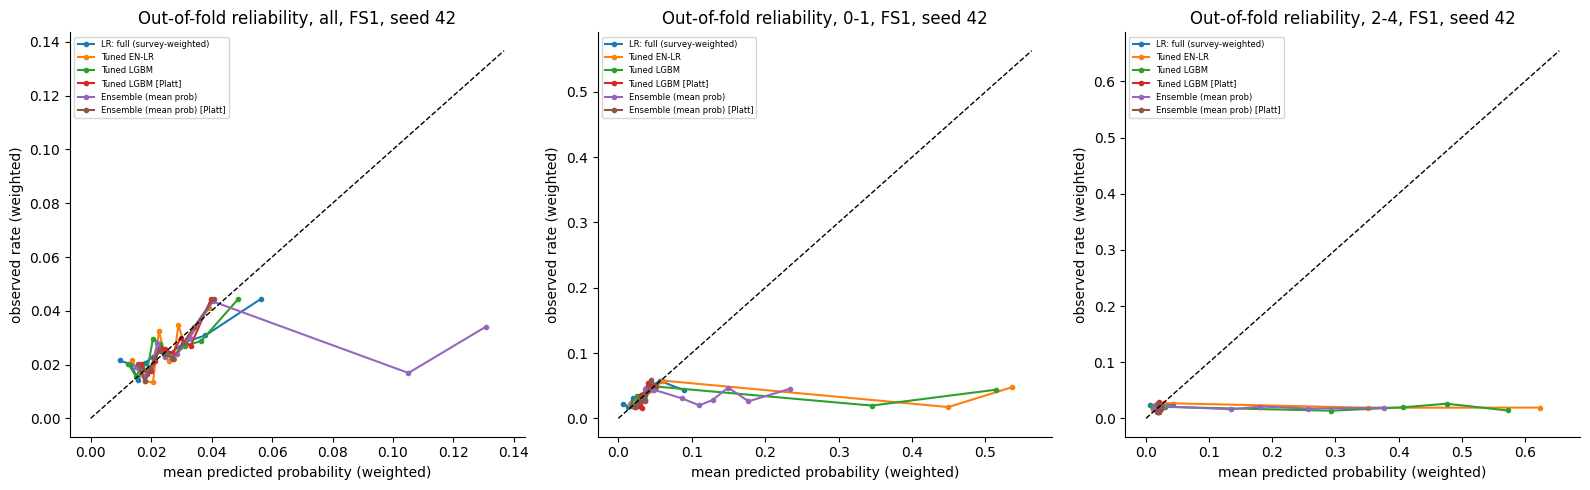

Nested operating points (threshold chosen inside the training part; mean over seeds), FS1:
cohort  fs                model  flagged_share_%  precision_w  recall_w  f1_w  f2_w  precision_u  recall_u  f1_u  f2_u
   0-1 FS1 Ensemble (mean prob)           41.217        0.043     0.521 0.080 0.162        0.044     0.541 0.081 0.166
   0-1 FS1       Tuned CatBoost           42.162        0.043     0.524 0.079 0.161        0.043     0.544 0.080 0.164
   0-1 FS1             Tuned DT           39.094        0.039     0.446 0.072 0.143        0.040     0.461 0.074 0.147
   0-1 FS1          Tuned EN-LR           39.169        0.044     0.507 0.081 0.162        0.045     0.526 0.083 0.167
   0-1 FS1           Tuned LGBM           47.135        0.042     0.579 0.079 0.164        0.043     0.611 0.081 0.169
   0-1 FS1             Tuned RF           42.297        0.044     0.554 0.082 0.168        0.045     0.569 0.083 0.171
   0-1 FS1            Tuned XGB           38.479        0.043     0.489 0.08

In [ ]:
# ===== 13. Calibration plots and honest operating points =====
def reliability(y, p, w, bins=10):
    q = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1))); idx = np.clip(np.digitize(p, q[1:-1], right=True), 0, len(q) - 2)
    return (np.array([np.average(p[idx == b], weights=w[idx == b]) for b in range(len(q) - 1)]),
            np.array([np.average(y[idx == b], weights=w[idx == b]) for b in range(len(q) - 1)]))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cohort in zip(axes, ['all', '0-1', '2-4']):
    R = RES[(cohort, 'FS1')]; s0 = SEEDS[0]
    cand = [REF_FULL, 'Tuned EN-LR', 'Tuned LGBM', 'Tuned LGBM [Platt]', M_ENS, M_ENS + ' [Platt]']
    for m in [c for c in cand if c in R['oof']]:
        xp, yo = reliability(R['y'], R['oof'][m][s0], R['w']); ax.plot(xp, yo, marker='o', ms=3, label=m)
    mx = ax.get_xlim()[1]; ax.plot([0, mx], [0, mx], 'k--', lw=1); ax.set_xlabel('mean predicted probability (weighted)'); ax.set_ylabel('observed rate (weighted)')
    ax.set_title(f'Out-of-fold reliability, {cohort}, FS1, seed {s0}'); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(f'{FIG}/calibration_fs1.png', dpi=130); plt.show()

op_rows = []
for (cohort, fs), R in RES.items():
    for model, d_ in R['oofbin'].items():
        for seed, b_ in d_.items():
            pr_w = prf(R['y'], b_, R['w']); pr_u = prf(R['y'], b_, np.ones_like(R['w']))
            op_rows.append({'cohort': cohort, 'fs': fs, 'model': model, 'seed': seed, 'flagged_share_%': 100 * b_.mean(), 'precision_w': pr_w[0], 'recall_w': pr_w[1], 'f1_w': pr_w[2], 'f2_w': pr_w[3],
                            'precision_u': pr_u[0], 'recall_u': pr_u[1], 'f1_u': pr_u[2], 'f2_u': pr_u[3]})
ops = pd.DataFrame(op_rows).groupby(['cohort', 'fs', 'model']).mean(numeric_only=True).drop(columns='seed').reset_index()
ops.to_csv(f'{OUT}/operating_points.csv', index=False)
with pd.option_context('display.width', 250):
    print('Nested operating points (threshold chosen inside the training part; mean over seeds), FS1:')
    print(ops[ops.fs == 'FS1'].round(3).to_string(index=False))
    print('\nFor reference the weighted prevalence is', {c: round(float(np.average(RES[(c, "FS1")]["y"], weights=RES[(c, "FS1")]["w"])), 4) for c in ('all', '0-1', '2-4')})

Held-out weighted AUC by outer fold (seed 42, FS1): fold-to-fold variability is large because each fold holds few cases
model        Ensemble (mean prob)  LR: age + sex (unweighted)  LR: full (survey-weighted)  Tuned CatBoost  Tuned EN-LR  Tuned LGBM  Tuned RF  Tuned XGB
cohort fold                                                                                                                                            
0-1    0                    0.644                       0.532                       0.622           0.644        0.626       0.649     0.628      0.651
       1                    0.617                       0.594                       0.609           0.627        0.635       0.608     0.589      0.615
       2                    0.570                       0.597                       0.565           0.557        0.581       0.593     0.604      0.583
       3                    0.591                       0.585                       0.581           0.588        0.561  

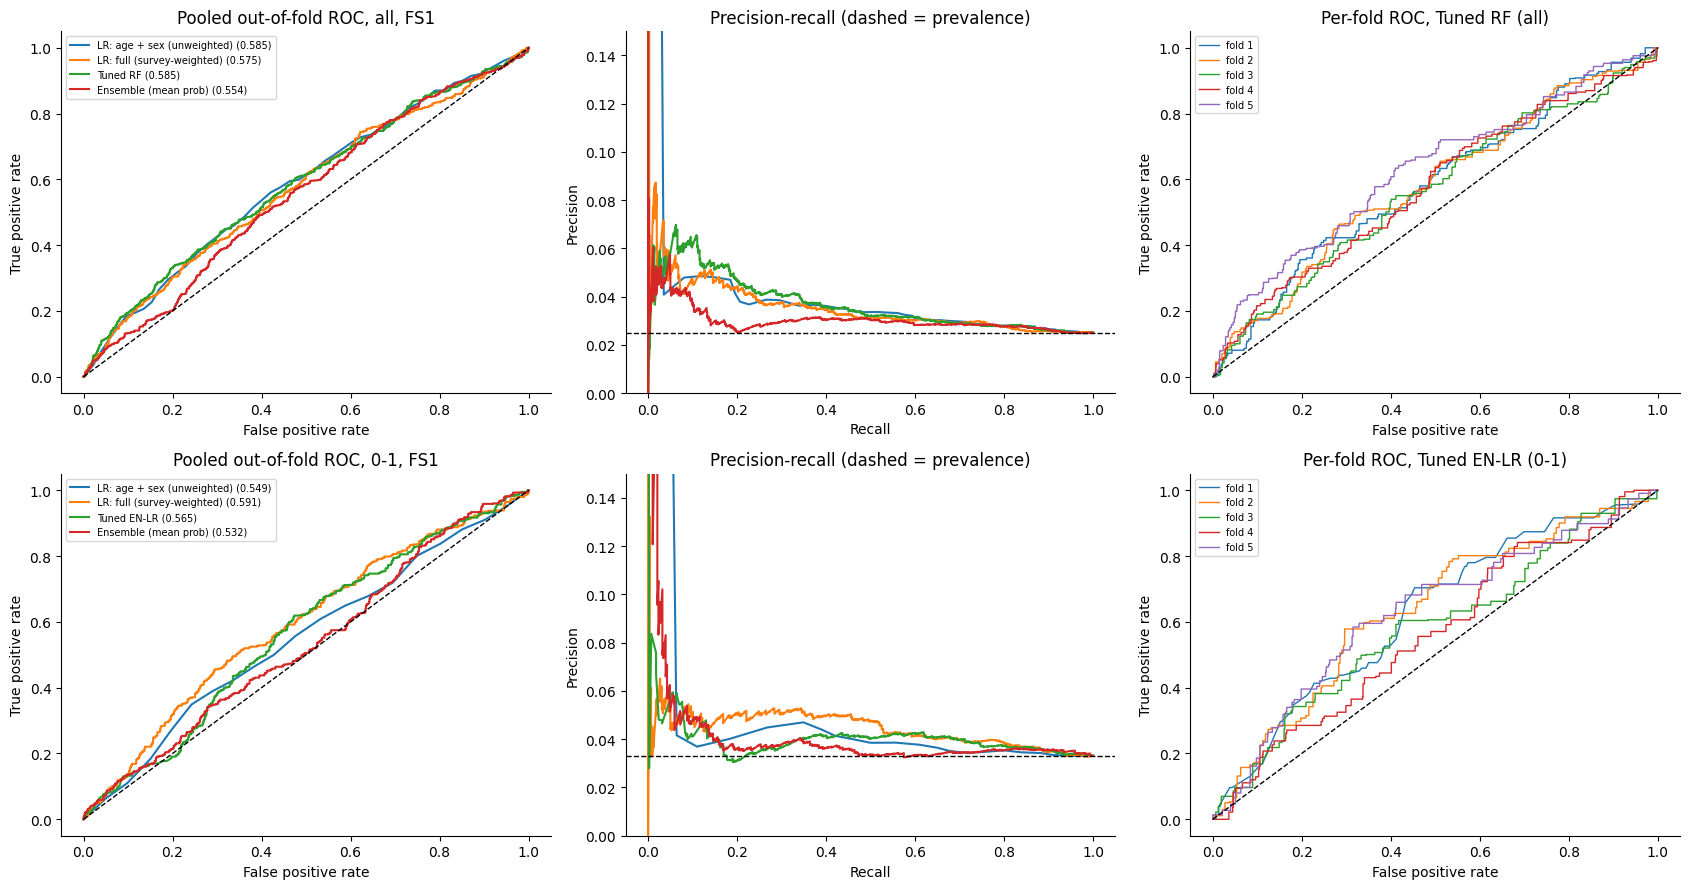

In [ ]:
# ===== 13b. Fold-by-fold AUC and ROC / PR curves (preserved from the original notebook, now for the tuned comparison) =====
TREE_FAMS = {'Tuned RF': 'RF', 'Tuned XGB': 'XGB', 'Tuned LGBM': 'LGBM', 'Tuned CatBoost': 'CB'}
ALL_FAMS = {**TREE_FAMS, 'Tuned EN-LR': 'EN', 'Tuned DT': 'DT'}
def best_family(cohort, fs, allowed):
    t = tbl[(tbl.cohort == cohort) & (tbl.fs == fs) & tbl.model.isin(list(allowed))]
    return None if t.empty else t.sort_values('auc_w_mean', ascending=False).iloc[0]['model']

key_ = [REF_AGE, REF_FULL, 'Tuned EN-LR', 'Tuned LGBM', 'Tuned XGB', 'Tuned RF', 'Tuned CatBoost', M_ENS]
ff = folds_all[(folds_all.fs == 'FS1') & (folds_all.seed == SEEDS[0]) & folds_all.model.isin(key_)]
fold_tab = ff.pivot_table(index=['cohort', 'fold'], columns='model', values='auc_w_test')
print(f'Held-out weighted AUC by outer fold (seed {SEEDS[0]}, FS1): fold-to-fold variability is large because each fold holds few cases')
print(fold_tab.round(3).to_string())
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for r_, cohort in enumerate(['all', '0-1']):
    R = RES[(cohort, 'FS1')]; s0 = SEEDS[0]; y_, w_ = R['y'], R['w']
    tuned_best = best_family(cohort, 'FS1', ALL_FAMS)
    for m in [REF_AGE, REF_FULL, tuned_best, M_ENS]:
        if m is None or m not in R['oof']: continue
        sc_ = R['oof'][m][s0]; fpr, tpr, _ = roc_curve(y_, sc_, sample_weight=w_); pr_, rc_, _ = precision_recall_curve(y_, sc_, sample_weight=w_)
        axes[r_, 0].plot(fpr, tpr, label=f'{m} ({safe_auc(y_, sc_, w_):.3f})'); axes[r_, 1].plot(rc_, pr_, label=m)
    axes[r_, 0].plot([0, 1], [0, 1], 'k--', lw=1); axes[r_, 0].set_title(f'Pooled out-of-fold ROC, {cohort}, FS1'); axes[r_, 0].legend(fontsize=7)
    axes[r_, 1].axhline(np.average(y_, weights=w_), color='k', ls='--', lw=1); axes[r_, 1].set_title('Precision-recall (dashed = prevalence)'); axes[r_, 1].set_ylim(0, max(0.15, 3 * np.average(y_, weights=w_)))
    if tuned_best is not None:                                  # per-fold ROC of the best tuned family (fold-to-fold variability)
        scb = R['oof'][tuned_best][s0]
        for fold, (tr_, te_) in enumerate(StratifiedGroupKFold(N_OUTER, shuffle=True, random_state=s0).split(np.zeros(len(y_)), y_, R['psu'])):
            fpr, tpr, _ = roc_curve(y_[te_], scb[te_], sample_weight=w_[te_]); axes[r_, 2].plot(fpr, tpr, lw=1, label=f'fold {fold + 1}')
        axes[r_, 2].plot([0, 1], [0, 1], 'k--', lw=1); axes[r_, 2].set_title(f'Per-fold ROC, {tuned_best} ({cohort})'); axes[r_, 2].legend(fontsize=7)
    for c_ in range(3): axes[r_, c_].set_xlabel('False positive rate' if c_ != 1 else 'Recall'); axes[r_, c_].set_ylabel('True positive rate' if c_ != 1 else 'Precision')
plt.tight_layout(); plt.savefig(f'{FIG}/roc_pr_fs1.png', dpi=130); plt.show()

## 14. Model selection: prefer the simplest stable model

**Pre-declared rule** (applied per cohort x feature set, using only the cross-validated results above):

1. A model counts as a *reproducible improvement* only if its paired AUC difference versus the **age + sex logistic regression** is positive in **every seed** and the PSU-bootstrap 95% CI of that difference excludes zero.
2. Among reproducible models whose seed-mean weighted AUC is within 0.005 of the best candidate, the **simplest** (order: baselines < ridge/full logistic < elastic net < tree < boosted models < forest < ensemble) is recommended.
3. If nothing is reproducibly better than age + sex, the recommendation is **age + sex logistic regression**.
4. Gains of about 0.02 AUC or more that fail rule 1 are labelled *provisional*.

Selecting among about fifteen candidates with the same out-of-fold predictions that are used to report them is itself slightly optimistic; a final untouched evaluation set (or external data) would be needed to confirm the recommended model.

In [ ]:
# ===== 14. Pre-declared model-selection rule =====
COMPLEXITY = [M_AGESEX_U, M_AGESEX_W, M_RIDGE, M_FULL_U, M_FULL_W, M_AUX_MU, M_AUX_TAIL, M_AUX_STACK, 'Tuned EN-LR', 'Tuned DT', 'Tuned XGB',
              'Tuned LGBM', 'Tuned CatBoost', 'Tuned RF', M_ENS]
sel_rows = []
for (cohort, fs), R in RES.items():
    t = bw[(bw.cohort == cohort) & (bw.fs == fs)].set_index('model'); tt = tbl[(tbl.cohort == cohort) & (tbl.fs == fs)].set_index('model')
    cand = [m for m in COMPLEXITY if m in t.index]
    best_m = max(cand, key=lambda m: t.loc[m, 'auc_seed_mean']); best_auc = t.loc[best_m, 'auc_seed_mean']
    repro = {m: (m == REF_AGE) or (t.loc[m, 'diff_age_sex_ci_lo'] > 0 and int(tt.loc[m, 'diff_age_sex_auc_w_seeds_positive']) == len(SEEDS)) for m in cand}
    rec = next((m for m in cand if repro[m] and t.loc[m, 'auc_seed_mean'] >= best_auc - 0.005), REF_AGE)
    sel_rows.append({'cohort': cohort, 'fs': fs, 'recommended_model': rec, 'rec_auc_w': t.loc[rec, 'auc_seed_mean'], 'rec_ci_lo': t.loc[rec, 'auc_ci_lo'], 'rec_ci_hi': t.loc[rec, 'auc_ci_hi'],
                     'rec_diff_vs_age_sex': t.loc[rec, 'diff_age_sex'], 'rec_diff_vs_age_sex_ci_lo': t.loc[rec, 'diff_age_sex_ci_lo'], 'rec_diff_vs_age_sex_ci_hi': t.loc[rec, 'diff_age_sex_ci_hi'],
                     'rec_diff_vs_full_w': t.loc[rec, 'diff_full_w'], 'best_by_auc': best_m, 'best_auc_w': best_auc,
                     'best_diff_vs_age_sex': t.loc[best_m, 'diff_age_sex'], 'best_reproducible': bool(repro[best_m]),
                     'best_is_provisional_gain': bool((not repro[best_m]) and t.loc[best_m, 'diff_age_sex'] >= 0.02),
                     'age_sex_auc_w': t.loc[REF_AGE, 'auc_seed_mean'], 'full_w_auc_w': t.loc[REF_FULL, 'auc_seed_mean']})
selection = pd.DataFrame(sel_rows); selection.to_csv(f'{OUT}/model_selection.csv', index=False)
final_cols = ['cohort', 'fs', 'model', 'auc_w_mean', 'auc_w_sd', 'boot_auc_w_ci_lo', 'boot_auc_w_ci_hi', 'auc_u_mean', 'ap_w_mean', 'ap_u_mean', 'prev_w_mean', 'prev_u_mean',
              'brier_w_mean', 'brier_u_mean', 'cal_int_w_mean', 'cal_slope_w_mean', 'cal_int_u_mean', 'cal_slope_u_mean', 'top10_w_mean', 'top10_u_mean',
              'fold_auc_w_mean', 'fold_auc_w_sd', 'diff_age_sex', 'diff_age_sex_ci_lo', 'diff_age_sex_ci_hi', 'diff_age_sex_auc_w_seeds_positive', 'diff_full_w', 'diff_full_w_ci_lo', 'diff_full_w_ci_hi',
              'diff_full_w_auc_w_seeds_positive', 'n_seeds']
tbl[final_cols].round(5).to_csv(f'{OUT}/final_model_comparison.csv', index=False)
with pd.option_context('display.width', 250, 'display.max_colwidth', 34):
    print(selection[['cohort', 'fs', 'recommended_model', 'rec_auc_w', 'rec_diff_vs_age_sex', 'rec_diff_vs_age_sex_ci_lo', 'rec_diff_vs_age_sex_ci_hi', 'best_by_auc', 'best_auc_w', 'best_reproducible', 'best_is_provisional_gain']].round(4).to_string(index=False))

cohort  fs          recommended_model  rec_auc_w  rec_diff_vs_age_sex  rec_diff_vs_age_sex_ci_lo  rec_diff_vs_age_sex_ci_hi                        best_by_auc  best_auc_w  best_reproducible  best_is_provisional_gain
   all FS0 LR: age + sex (unweighted)     0.5837               0.0000                     0.0000                     0.0000                Aux WHZ: stacked LR      0.5876              False                     False
   all FS1 LR: age + sex (unweighted)     0.5837               0.0000                     0.0000                     0.0000                Aux WHZ: stacked LR      0.5874              False                     False
   all FS2 LR: age + sex (unweighted)     0.5837               0.0000                     0.0000                     0.0000                        Tuned EN-LR      0.5974              False                     False
   0-1 FS0 LR: age + sex (unweighted)     0.5476               0.0000                     0.0000                     0.0000             

## 15. Permutation check and SHAP (finalist only)

* **Permutation check.** For the best tuned family in each primary analysis (FS1), the outcome labels are shuffled and the pooled out-of-fold AUC is recomputed with the same folds and the configuration chosen in the real run. This checks that the real AUC exceeds what the pipeline produces when there is no signal. It is a sanity check of the pipeline, not a significance test of the model.
* **SHAP** is optional and runs only for the best tuned tree family per primary analysis, computed **out of fold** (each fold's model is refitted on its training part and explained on its held-out children, using the configuration chosen for that fold). No SHAP value is used to select features.

In [ ]:
# ===== 15a. Permutation null for the best tuned family (FS1) =====
def cohort_data(cohort, fs):
    m = COHORT_MASK[cohort]; frame = XFRAME.loc[m].reset_index(drop=True); feats = FEATURE_SETS[cohort][fs]
    return frame, frame[feats], feats, Y[m], W[m], PSU[m]

def fold_setup(cohort, fs, seed):
    frame, Xdf, feats, y, w, psu = cohort_data(cohort, fs); fr = RES[(cohort, fs)]['folds']
    splits = list(StratifiedGroupKFold(N_OUTER, shuffle=True, random_state=seed).split(Xdf, y, psu)); out = []
    for fold, (tr, te) in enumerate(splits):
        pre = build_preproc(feats, frame).fit(Xdf.iloc[tr]); out.append((tr, te, pre.transform(Xdf.iloc[tr]), pre.transform(Xdf.iloc[te]), list(pre.get_feature_names_out())))
    return out, y, w, feats

perm_rows = []
for cohort in ['all', '0-1', '2-4']:
    if (cohort, 'FS1') not in RES: continue
    lab = best_family(cohort, 'FS1', ALL_FAMS)
    if lab is None: continue
    fam = ALL_FAMS[lab]; seed = SEEDS[0]; setup, y, w, feats = fold_setup(cohort, 'FS1', seed)
    fr = RES[(cohort, 'FS1')]['folds']; fr = fr[(fr.model == lab) & (fr.seed == seed)].sort_values('fold'); cfgs = [json.loads(p) for p in fr['params']]
    def pooled_auc(yy):
        s = np.zeros(len(yy))
        for (tr, te, Xtr, Xte, _), cfg in zip(setup, cfgs): s[te] = predict_p(fit_est(fam, cfg, Xtr, yy[tr], w[tr], seed), Xte)
        return safe_auc(yy, s, w)
    obs = pooled_auc(y); rng = np.random.RandomState(7); null = np.array([pooled_auc(rng.permutation(y)) for _ in range(N_PERM)])
    perm_rows.append({'cohort': cohort, 'family': lab, 'observed_auc_w': obs, 'perm_mean': null.mean(), 'perm_sd': null.std(), 'perm_max': null.max(), 'n_perm': N_PERM,
                      'p_value': (1 + (null >= obs).sum()) / (1 + N_PERM)})
    print(f'{cohort}: {lab} observed AUC {obs:.4f} | permuted mean {null.mean():.4f} (SD {null.std():.4f}, max {null.max():.4f}) | p = {perm_rows[-1]["p_value"]:.3f} with {N_PERM} permutations')
perm_df = pd.DataFrame(perm_rows); perm_df.to_csv(f'{OUT}/permutation_check.csv', index=False)

all: Tuned RF observed AUC 0.5850 | permuted mean 0.4911 (SD 0.0174, max 0.5334) | p = 0.032 with 30 permutations


0-1: Tuned EN-LR observed AUC 0.5646 | permuted mean 0.4893 (SD 0.0216, max 0.5461) | p = 0.032 with 30 permutations


2-4: Tuned XGB observed AUC 0.5166 | permuted mean 0.4922 (SD 0.0246, max 0.5446) | p = 0.194 with 30 permutations


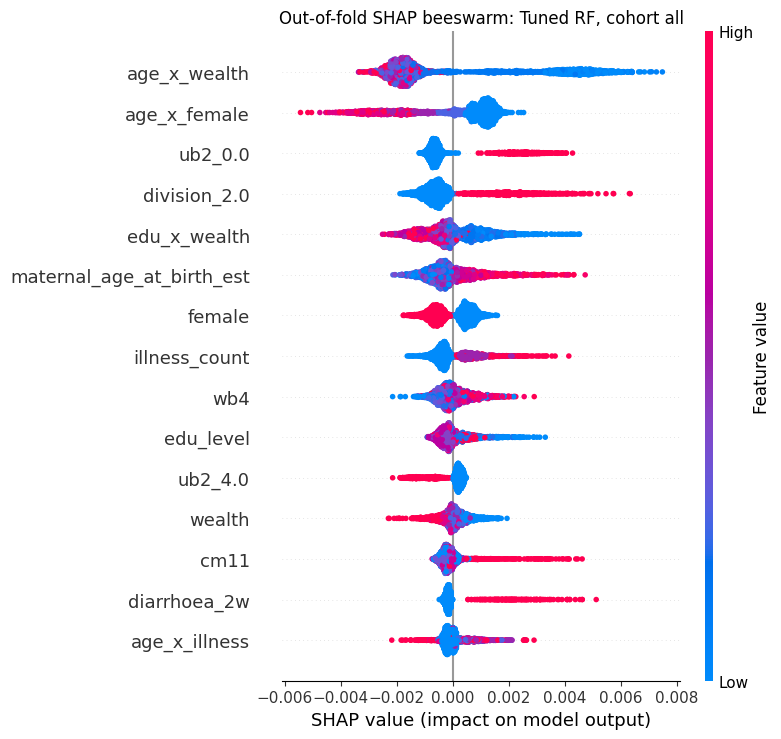

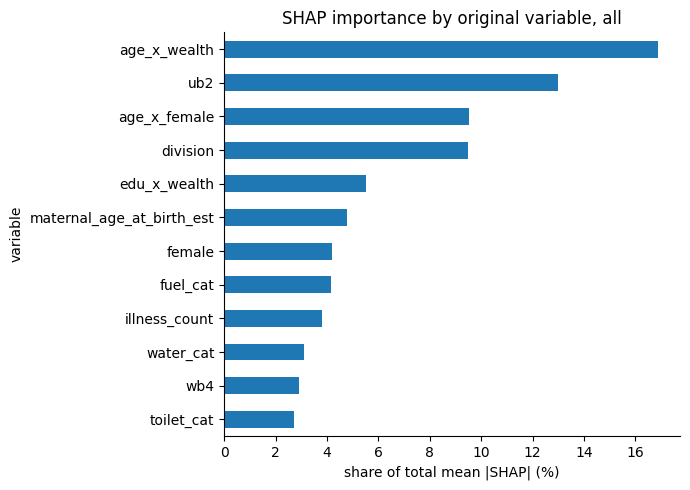

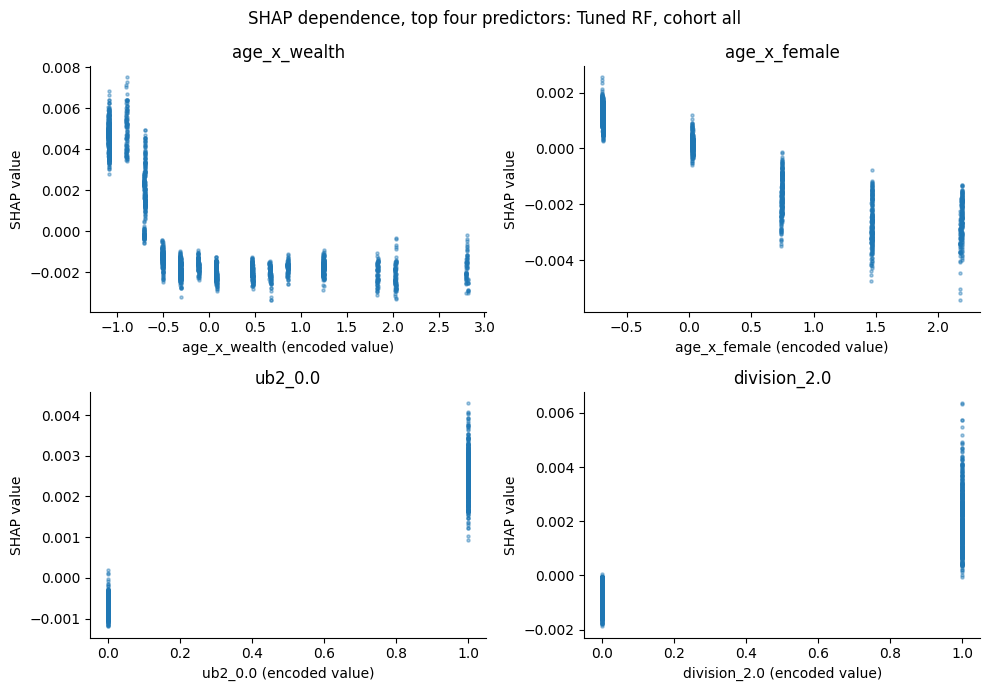

all: Tuned RF. Top variables by SHAP share (%): {'age_x_wealth': 16.9, 'ub2': 13.0, 'age_x_female': 9.5, 'division': 9.5, 'edu_x_wealth': 5.5, 'maternal_age_at_birth_est': 4.8, 'female': 4.2, 'fuel_cat': 4.1}


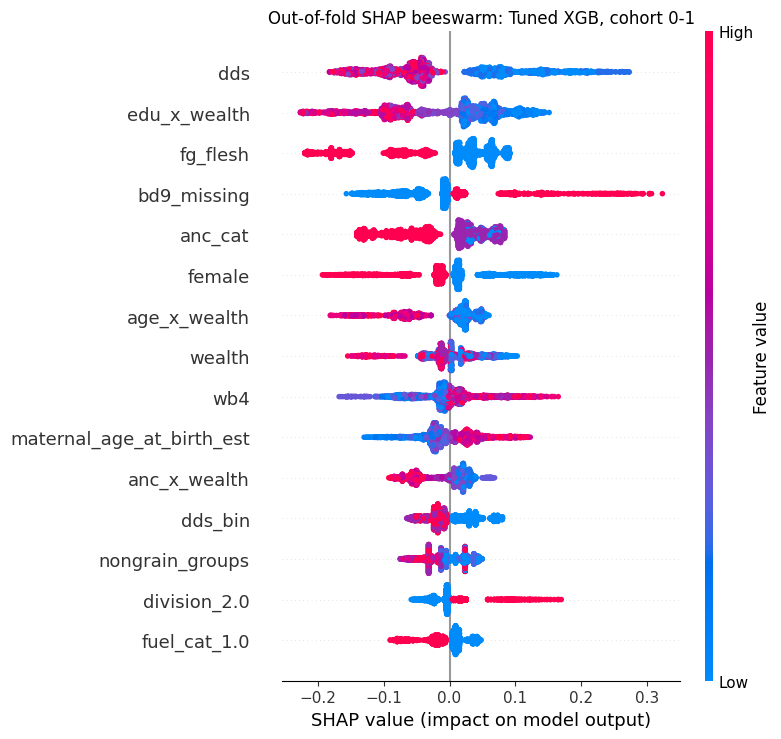

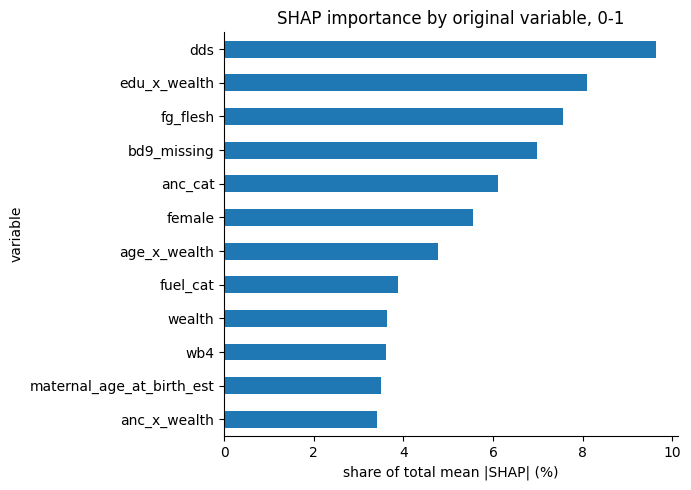

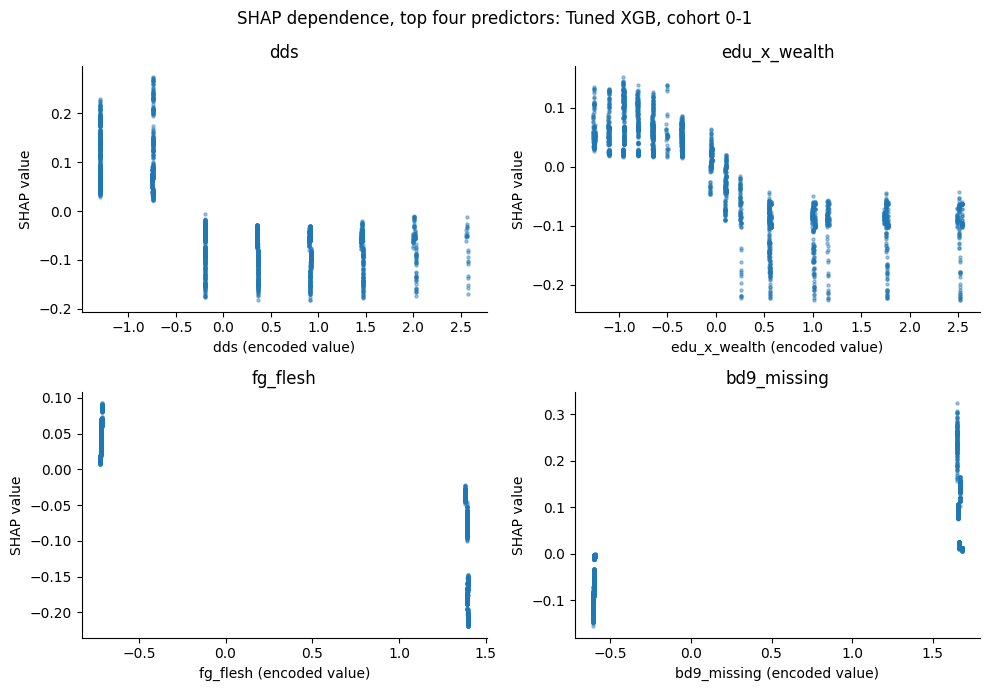

0-1: Tuned XGB. Top variables by SHAP share (%): {'dds': 9.600000381469727, 'edu_x_wealth': 8.100000381469727, 'fg_flesh': 7.599999904632568, 'bd9_missing': 7.0, 'anc_cat': 6.099999904632568, 'female': 5.599999904632568, 'age_x_wealth': 4.800000190734863, 'fuel_cat': 3.9000000953674316}
   diet-related variables together: 29.8% of SHAP importance (descriptive only; not used for selection)


In [ ]:
# ===== 15b. Out-of-fold SHAP for the best tuned tree family (FS1) =====
def base_variable(name, feats):
    hits = [f for f in feats if name == f or name.startswith(f + '_')]
    return max(hits, key=len) if hits else name

shap_summary = {}
if not RUN_SHAP:
    print('SHAP skipped (package missing or WASTING_SHAP=0).')
else:
    import shap
    for cohort in ['all', '0-1']:
        if (cohort, 'FS1') not in RES: continue
        lab = best_family(cohort, 'FS1', TREE_FAMS)
        if lab is None: continue
        fam = TREE_FAMS[lab]; seed = SEEDS[0]; setup, y, w, feats = fold_setup(cohort, 'FS1', seed)
        fr = RES[(cohort, 'FS1')]['folds']; fr = fr[(fr.model == lab) & (fr.seed == seed)].sort_values('fold'); cfgs = [json.loads(p) for p in fr['params']]
        S_list, X_list, rng = [], [], np.random.RandomState(11)
        try:
            for (tr, te, Xtr, Xte, names), cfg in zip(setup, cfgs):
                est = fit_est(fam, cfg, Xtr, y[tr], w[tr], seed); sub = rng.choice(len(te), size=min(SHAP_N, len(te)), replace=False)
                sv = shap.TreeExplainer(est).shap_values(Xte[sub])
                sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
                S_list.append(pd.DataFrame(sv, columns=names)); X_list.append(pd.DataFrame(Xte[sub], columns=names))
            S_df = pd.concat(S_list, ignore_index=True); X_df = pd.concat(X_list, ignore_index=True)
            imp = S_df.abs().mean().rename('mean_abs_shap').reset_index().rename(columns={'index': 'feature'}); imp['variable'] = imp['feature'].map(lambda n: base_variable(n, feats))
            grp = imp.groupby('variable')['mean_abs_shap'].sum().sort_values(ascending=False); grp_share = (grp / grp.sum() * 100).rename('share_%')
            imp.sort_values('mean_abs_shap', ascending=False).to_csv(f'{OUT}/shap_importance_{cohort}.csv', index=False); grp_share.to_csv(f'{OUT}/shap_group_share_{cohort}.csv')
            shap_summary[cohort] = (lab, grp_share)
            plt.figure(figsize=(9, 6)); shap.summary_plot(S_df.values, X_df.values, feature_names=list(S_df.columns), max_display=15, show=False)
            plt.title(f'Out-of-fold SHAP beeswarm: {lab}, cohort {cohort}'); plt.tight_layout(); plt.savefig(f'{FIG}/shap_beeswarm_{cohort}.png', dpi=130); plt.show()
            plt.figure(figsize=(7, 5)); grp_share.head(12)[::-1].plot.barh(); plt.xlabel('share of total mean |SHAP| (%)'); plt.title(f'SHAP importance by original variable, {cohort}')
            plt.tight_layout(); plt.savefig(f'{FIG}/shap_group_bar_{cohort}.png', dpi=130); plt.show()
            top4 = list(imp.sort_values('mean_abs_shap', ascending=False)['feature'].iloc[:4])
            fig, axs = plt.subplots(2, 2, figsize=(10, 7))
            for ax, f_ in zip(axs.ravel(), top4):
                ax.scatter(X_df[f_], S_df[f_], s=5, alpha=0.4); ax.set_xlabel(f'{f_} (encoded value)'); ax.set_ylabel('SHAP value'); ax.set_title(f_)
            plt.suptitle(f'SHAP dependence, top four predictors: {lab}, cohort {cohort}'); plt.tight_layout(); plt.savefig(f'{FIG}/shap_dependence_{cohort}.png', dpi=130); plt.show()
            print(f'{cohort}: {lab}. Top variables by SHAP share (%):', grp_share.head(8).round(1).to_dict())
            if cohort == '0-1':
                diet = [v for v in grp_share.index if v in INFANT_BASE[:8] + ['dds_bin', 'dds_ge2', 'dds_ge4', 'nongrain_groups', 'dds_x_age']]
                print(f'   diet-related variables together: {grp_share[diet].sum():.1f}% of SHAP importance (descriptive only; not used for selection)')
        except Exception as e:
            print(f'SHAP failed for {cohort}: {repr(e)[:200]}')

## 16. Findings, files and limitations

The next cell builds the summary **directly from the saved result tables**, so it cannot disagree with the numbers above. Its verdict follows the pre-declared rule in section 14. Reference values from the earlier notebook (0.587 weighted AUC for age + sex on all children, 0.595 for a tuned random forest under age 2) are printed only for context: they came from a single fold partition and different library versions, so they are not directly comparable.

In [ ]:
# ===== 16. Auto-generated findings, manifest =====
print('=' * 100); print(f'FINDINGS (profile={PROFILE}, seeds={SEEDS}, tuning iterations={N_TUNE_ITER}, bootstrap={N_BOOT})'); print('=' * 100)
REF_OLD = {'all': 0.587, '0-1': 0.595}
for cohort in ['all', '0-1', '2-4']:
    s_ = selection[selection.cohort == cohort]
    if s_.empty: continue
    n_ = len(RES[(cohort, 'FS1')]['y']); ev_ = int(RES[(cohort, 'FS1')]['y'].sum())
    print(f'\n--- cohort {cohort}: {n_:,} children, {ev_} cases ---')
    for _, r in s_.iterrows():
        verdict = ('REPRODUCIBLE improvement over age + sex' if r.recommended_model != REF_AGE else
                   ('No reproducible improvement over age + sex' + ('; best model shows a PROVISIONAL gain of >= 0.02 AUC that failed the seed/CI test' if r.best_is_provisional_gain else '')))
        print(f'{r.fs}: age+sex AUC {r.age_sex_auc_w:.3f} | full survey-weighted LR {r.full_w_auc_w:.3f} | best by AUC: {r.best_by_auc} {r.best_auc_w:.3f} (diff vs age+sex {r.best_diff_vs_age_sex:+.3f}, reproducible={r.best_reproducible})')
        print(f'      recommended: {r.recommended_model} (AUC {r.rec_auc_w:.3f}, 95% CI {r.rec_ci_lo:.3f}-{r.rec_ci_hi:.3f}; diff vs age+sex {r.rec_diff_vs_age_sex:+.3f} [{r.rec_diff_vs_age_sex_ci_lo:+.3f}, {r.rec_diff_vs_age_sex_ci_hi:+.3f}]) -> {verdict}')
    if cohort in REF_OLD: print(f'   (earlier-notebook reference, not directly comparable: {REF_OLD[cohort]:.3f})')
gp = gaps[(gaps.fs == 'FS1') & gaps.model.str.startswith('Tuned') & ~gaps.model.str.contains('Platt')]
print('\nMeasured optimism gaps for tuned models (FS1, mean over folds and seeds):')
print(gp[['cohort', 'model', 'auc_w_train_mean', 'auc_w_test_mean', 'apparent_gap_auc_mean', 'tuning_gap_auc_mean']].round(3).to_string(index=False))

fail_n = sum(len(R['failed']) for R in RES.values())
print(f'\nModel fits that failed and were skipped: {fail_n}')
if fail_n:
    for R in RES.values(): print('  ', R['cohort'], R['fs'], R['failed'][:3])
not_run = ['FS2 (revised file not found)' if not HAVE_REVISED else None, 'SHAP (package missing or disabled)' if not RUN_SHAP else None]
print('Analyses not run:', [x for x in not_run if x] or 'none')

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()
manifest = {'profile': PROFILE, 'seeds': list(SEEDS), 'outer_folds': N_OUTER, 'inner_folds': N_INNER, 'tune_iterations': N_TUNE_ITER, 'n_boot': N_BOOT, 'n_perm': N_PERM,
            'n_jobs': N_JOBS, 'have_revised': HAVE_REVISED, 'run_shap': RUN_SHAP, 'optional_packages': OPTIONAL, 'python': platform.python_version(),
            'versions': {m: getattr(sys.modules.get(m), '__version__', None) for m in ['numpy', 'pandas', 'sklearn', 'scipy', 'xgboost', 'lightgbm', 'catboost', 'shap'] if m in sys.modules},
            'data_file': os.path.basename(orig_path), 'data_sha256': sha256(orig_path), 'rows_used': int(len(df)), 'runtime_minutes': round((time.time() - T_START) / 60, 1),
            'outputs': sorted(os.listdir(OUT)), 'figures': sorted(os.listdir(FIG))}
json.dump(manifest, open(f'{OUT}/run_manifest.json', 'w'), indent=2, default=str)
print(f'\nSaved: {len(manifest["outputs"])} files in {OUT}/ and {len(manifest["figures"])} figures in {FIG}/. Total runtime {manifest["runtime_minutes"]} min.')

FINDINGS (profile=standard, seeds=(42, 43, 44), tuning iterations=4, bootstrap=300)

--- cohort all: 22,311 children, 552 cases ---
FS0: age+sex AUC 0.584 | full survey-weighted LR 0.581 | best by AUC: Aux WHZ: stacked LR 0.588 (diff vs age+sex +0.004, reproducible=False)
      recommended: LR: age + sex (unweighted) (AUC 0.584, 95% CI 0.557-0.611; diff vs age+sex +0.000 [+0.000, +0.000]) -> No reproducible improvement over age + sex
FS1: age+sex AUC 0.584 | full survey-weighted LR 0.580 | best by AUC: Aux WHZ: stacked LR 0.587 (diff vs age+sex +0.004, reproducible=False)
      recommended: LR: age + sex (unweighted) (AUC 0.584, 95% CI 0.557-0.611; diff vs age+sex +0.000 [+0.000, +0.000]) -> No reproducible improvement over age + sex
FS2: age+sex AUC 0.584 | full survey-weighted LR 0.583 | best by AUC: Tuned EN-LR 0.597 (diff vs age+sex +0.014, reproducible=False)
      recommended: LR: age + sex (unweighted) (AUC 0.584, 95% CI 0.557-0.611; diff vs age+sex +0.000 [+0.000, +0.000]) -> N

### Limitations (read before using any number above)

* **Weak signal.** Even the best predictors here rank cases only modestly better than chance; none of the models is accurate enough for individual-level decisions, and probabilities of complex models are often over-confident (see calibration slopes).
* **Out-of-fold evaluation only.** Training scores and in-sample scores are shown only as diagnostics of memorisation; the in-sample trap in section 7b is a warning, not a result.
* **Model choice by the same predictions.** The selection rule and the reported intervals use the same out-of-fold predictions; the cluster bootstrap resamples PSUs but does not re-run tuning, so intervals understate total uncertainty. Seed repeats capture fold-assignment noise only.
* **Weighted metrics are not design-based inference.** `chweight` is used as a predictive weight; standard errors do not account for stratification or clustering beyond the PSU bootstrap.
* **FS2 is post hoc** (variables chosen after earlier exploratory analyses of this data) and may be optimistic; the birth variables are mother-reported and exist only for ages 0-1.
* **Heuristic features.** WASH / asset composites and maternal age at birth (`wb4 - ub2`, age in whole years) depend on coding that must be verified against the codebook.
* **Small subgroups.** The 0-1 and 2-4 cohorts have few events per fold; tuned results there are noisy and the 2-4 cohort uses a reduced model list.
* **Limited tuning budget.** A small randomised search with a fixed conservative anchor per family was used for compute reasons; a larger budget (`WASTING_PROFILE=extended`) may change the ranking of tuned models.
* **No external validation or causal interpretation.**